In [67]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd


# 1. PDO 1

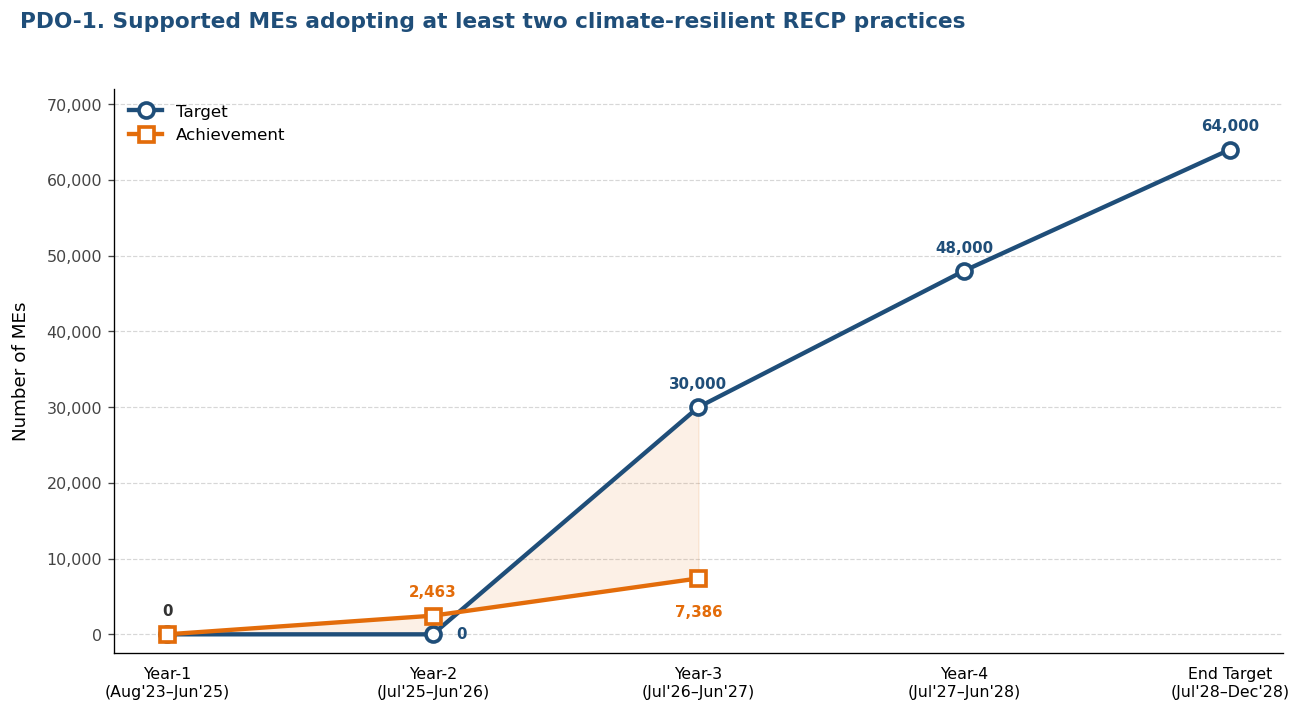

In [ ]:
# PDO 1
years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 0, 30000, 48000, 64000]
achievement = [0, 2463, 7386, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Plot lines
# ------------------------------------------------------------------
ax.plot(years, target, marker="o", markersize=9, linewidth=2.6,
        color="#1f4e79", markerfacecolor="white", markeredgewidth=2.2,
        label="Target", zorder=3)

ax.plot(years, achievement, marker="s", markersize=9, linewidth=2.6,
        color="#E36C0A", markerfacecolor="white", markeredgewidth=2.2,
        label="Achievement", zorder=4)

# ------------------------------------------------------------------
# 4. Shade the gap
# ------------------------------------------------------------------
x = np.arange(len(years))
target_arr = np.array(target, dtype=float)
ach_arr    = np.array(achievement, dtype=float)
mask       = ~np.isnan(ach_arr)
ax.fill_between(x[mask], ach_arr[mask], target_arr[mask],
                color="#E36C0A", alpha=0.10, zorder=1)

# ------------------------------------------------------------------
# 5. Data labels
#    Year-1 (0): single shared "0" above the point
#    Year-2 (1): achievement "2,463" ABOVE the square
#                target "0" placed to the RIGHT of the circle, vertically
#                centred on the line (dy = 0)
#    Other years: default offsets
# ------------------------------------------------------------------
def add_labels(values, color, default_xy, overrides=None, skip=None):
    overrides = overrides or {}
    skip = skip or set()
    for i, v in enumerate(values):
        if np.isnan(v) or i in skip:
            continue
        dx, dy, ha = overrides.get(i, default_xy)
        ax.annotate(f"{int(v):,}",
                    xy=(i, v), xytext=(dx, dy),
                    textcoords="offset points",
                    ha=ha, va="center",
                    fontsize=9, fontweight="bold", color=color)

# Achievement labels
add_labels(achievement, "#E36C0A", default_xy=(0, -20, "center"),
           overrides={1: (0, 14, "center")},   # Year-2 → above square
           skip={0})

# Target labels
add_labels(target, "#1f4e79", default_xy=(0, 14, "center"),
           overrides={1: (14, 0, "left")},     # Year-2 → right of circle, on the line
           skip={0})

# Shared "0" at Year-1 (both = 0)
ax.annotate("0",
            xy=(0, 0), xytext=(0, 14),
            textcoords="offset points",
            ha="center", va="center",
            fontsize=9, fontweight="bold", color="#333333")

# ------------------------------------------------------------------
# 6. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(-2500, 72000)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_ylabel("Number of MEs", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 7. Title
# ------------------------------------------------------------------
fig.suptitle(
    "PDO-1. Supported MEs adopting at least two climate-resilient RECP practices",
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)

# ------------------------------------------------------------------
# 8. Legend
# ------------------------------------------------------------------
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 9. Layout & save
# ------------------------------------------------------------------
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("1. pdo1_progress_line.jpg", dpi=200, bbox_inches="tight")
plt.show()

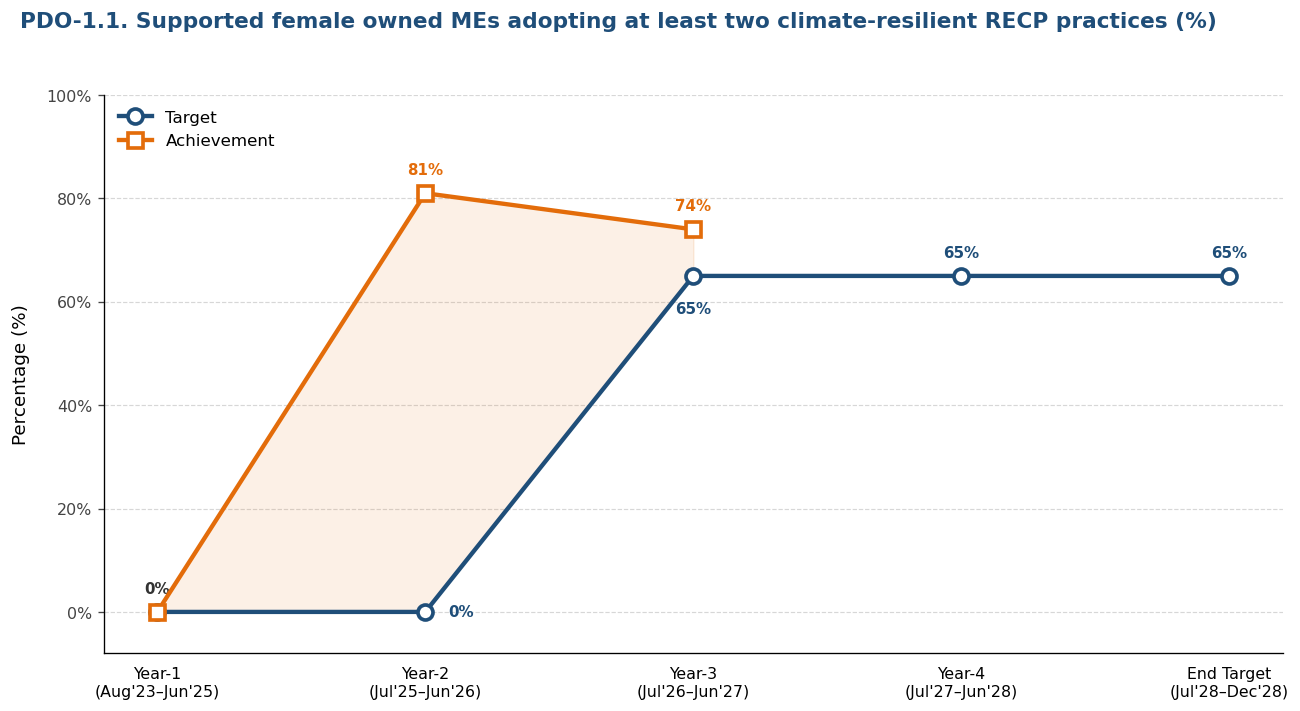

In [5]:

# PDO 1.1
years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 0, 65, 65, 65]
achievement = [0, 81, 74, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Plot lines
# ------------------------------------------------------------------
ax.plot(years, target, marker="o", markersize=9, linewidth=2.6,
        color="#1f4e79", markerfacecolor="white", markeredgewidth=2.2,
        label="Target", zorder=3)

ax.plot(years, achievement, marker="s", markersize=9, linewidth=2.6,
        color="#E36C0A", markerfacecolor="white", markeredgewidth=2.2,
        label="Achievement", zorder=4)

# ------------------------------------------------------------------
# 4. Shade the gap (achievement vs target where both exist)
# ------------------------------------------------------------------
x = np.arange(len(years))
target_arr = np.array(target, dtype=float)
ach_arr    = np.array(achievement, dtype=float)
mask       = ~np.isnan(ach_arr)
ax.fill_between(x[mask], ach_arr[mask], target_arr[mask],
                color="#E36C0A", alpha=0.10, zorder=1)

# ------------------------------------------------------------------
# 5. Data labels
#    Year-1 (0): single shared "0%" above the point
#    Year-2 (1): achievement "81%" ABOVE the square
#                target "0%" to the RIGHT of the circle, on the line
#    Year-3 (2): both labels — achievement above, target below
#    Other years: default offsets
# ------------------------------------------------------------------
def add_labels(values, color, default_xy, overrides=None, skip=None):
    overrides = overrides or {}
    skip = skip or set()
    for i, v in enumerate(values):
        if np.isnan(v) or i in skip:
            continue
        dx, dy, ha = overrides.get(i, default_xy)
        ax.annotate(f"{int(v)}%",
                    xy=(i, v), xytext=(dx, dy),
                    textcoords="offset points",
                    ha=ha, va="center",
                    fontsize=9, fontweight="bold", color=color)

# Achievement labels
add_labels(achievement, "#E36C0A", default_xy=(0, 14, "center"),
           overrides={1: (0, 14, "center"),      # Year-2 → above square
                      2: (0, 14, "center")},     # Year-3 → above square
           skip={0})

# Target labels
add_labels(target, "#1f4e79", default_xy=(0, 14, "center"),
           overrides={1: (14, 0, "left"),        # Year-2 → right of circle, on line
                      2: (0, -20, "center"),     # Year-3 → below circle
                      3: (0, 14, "center"),      # Year-4 → above
                      4: (0, 14, "center")},     # End Target → above
           skip={0})

# Shared "0%" at Year-1 (both = 0)
ax.annotate("0%",
            xy=(0, 0), xytext=(0, 14),
            textcoords="offset points",
            ha="center", va="center",
            fontsize=9, fontweight="bold", color="#333333")

# ------------------------------------------------------------------
# 6. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(-8, 100)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v)}%"))
ax.set_ylabel("Percentage (%)", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 7. Title
# ------------------------------------------------------------------
fig.suptitle(
    "PDO-1.1. Supported female owned MEs adopting at least two "
    "climate-resilient RECP practices (%)",
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)

# ------------------------------------------------------------------
# 8. Legend
# ------------------------------------------------------------------
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 9. Layout & save
# ------------------------------------------------------------------
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("1.1 pdo1_1.1_female_me_percent.jpg", dpi=200, bbox_inches="tight")
plt.show()

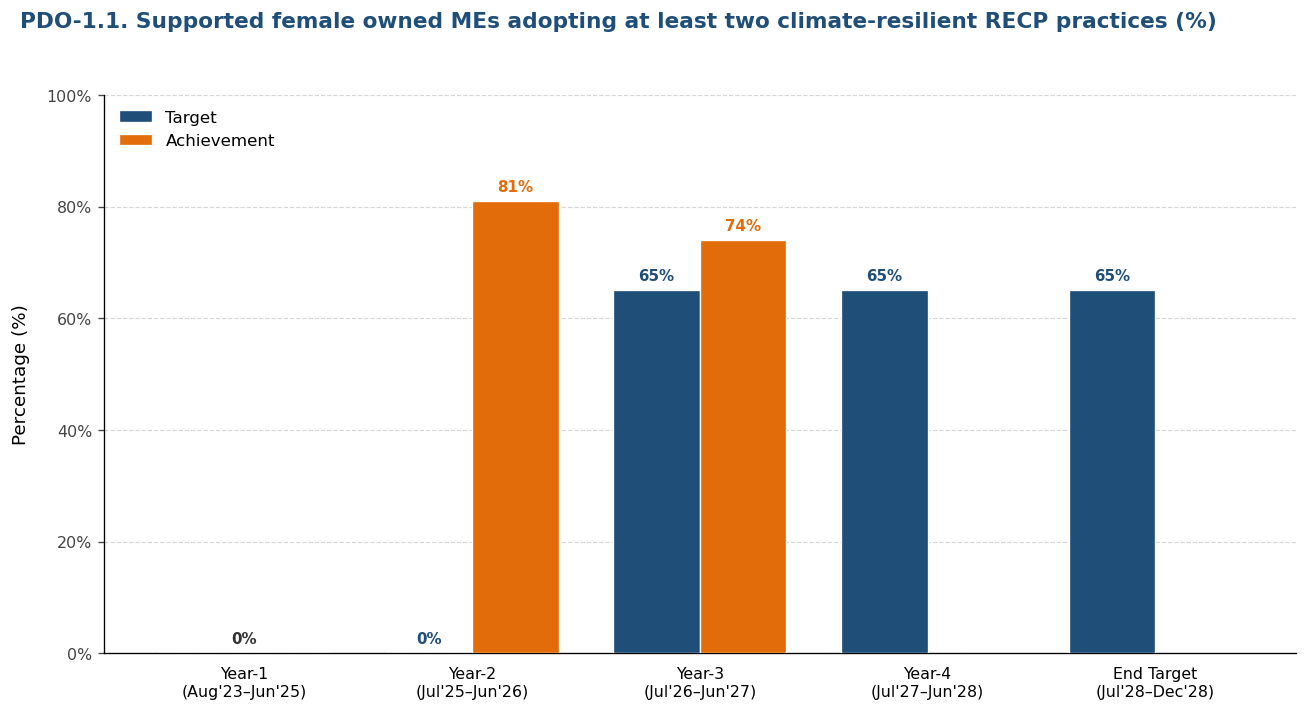

In [77]:
# PDO 1.1
years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 0, 65, 65, 65]
achievement = [0, 81, 74, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Grouped bars
# ------------------------------------------------------------------
x = np.arange(len(years))
bar_width = 0.38

# Target bars (blue) — replace NaN with 0 for plotting only
target_plot = np.array([v if not np.isnan(v) else 0 for v in target], dtype=float)

# Achievement bars (orange) — replace NaN with 0 for plotting only
ach_plot = np.array([v if not np.isnan(v) else 0 for v in achievement], dtype=float)
ach_mask = ~np.isnan(np.array(achievement, dtype=float))   # True where real data exists

bars_target = ax.bar(x - bar_width/2, target_plot, width=bar_width,
                     color="#1f4e79", edgecolor="white", linewidth=0.8,
                     label="Target", zorder=3)

bars_ach = ax.bar(x + bar_width/2, ach_plot, width=bar_width,
                  color="#E36C0A", edgecolor="white", linewidth=0.8,
                  label="Achievement", zorder=3)

# Hide the achievement bars that have no data (Years 4 & End Target)
for i, bar in enumerate(bars_ach):
    if not ach_mask[i]:
        bar.set_visible(False)

# ------------------------------------------------------------------
# 4. Data labels on bars
# ------------------------------------------------------------------
def bar_labels(bars, values, color, formatter, skip_idx=set(), visible_mask=None):
    for i, (bar, v) in enumerate(zip(bars, values)):
        if i in skip_idx:
            continue
        if visible_mask is not None and not visible_mask[i]:
            continue
        h = bar.get_height()
        ax.annotate(formatter(v),
                    xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha="center", va="bottom",
                    fontsize=9, fontweight="bold", color=color)

# Target labels — skip Year-1 (value 0, shares the "0%" with achievement)
bar_labels(bars_target, target, "#1f4e79",
           formatter=lambda v: f"{int(v)}%",
           skip_idx={0})

# Achievement labels — skip Year-1 (handled below), skip NaN bars
bar_labels(bars_ach, achievement, "#E36C0A",
           formatter=lambda v: f"{int(v)}%",
           skip_idx={0},
           visible_mask=ach_mask)

# Shared "0%" above Year-1 group (both target & achievement = 0)
ax.annotate("0%",
            xy=(0, 0), xytext=(0, 4),
            textcoords="offset points",
            ha="center", va="bottom",
            fontsize=9, fontweight="bold", color="#333333")

# ------------------------------------------------------------------
# 5. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v)}%"))
ax.set_ylabel("Percentage (%)", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 6. Title
# ------------------------------------------------------------------
fig.suptitle(
    "PDO-1.1. Supported female owned MEs adopting at least two "
    "climate-resilient RECP practices (%)",
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)

# ------------------------------------------------------------------
# 7. Legend
# ------------------------------------------------------------------
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 8. Layout & save
# ------------------------------------------------------------------
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("1aa pdo1_1.1_female_me_percent bar diagram.jpg", dpi=200, bbox_inches="tight")
plt.show()

# 2. PDO 2

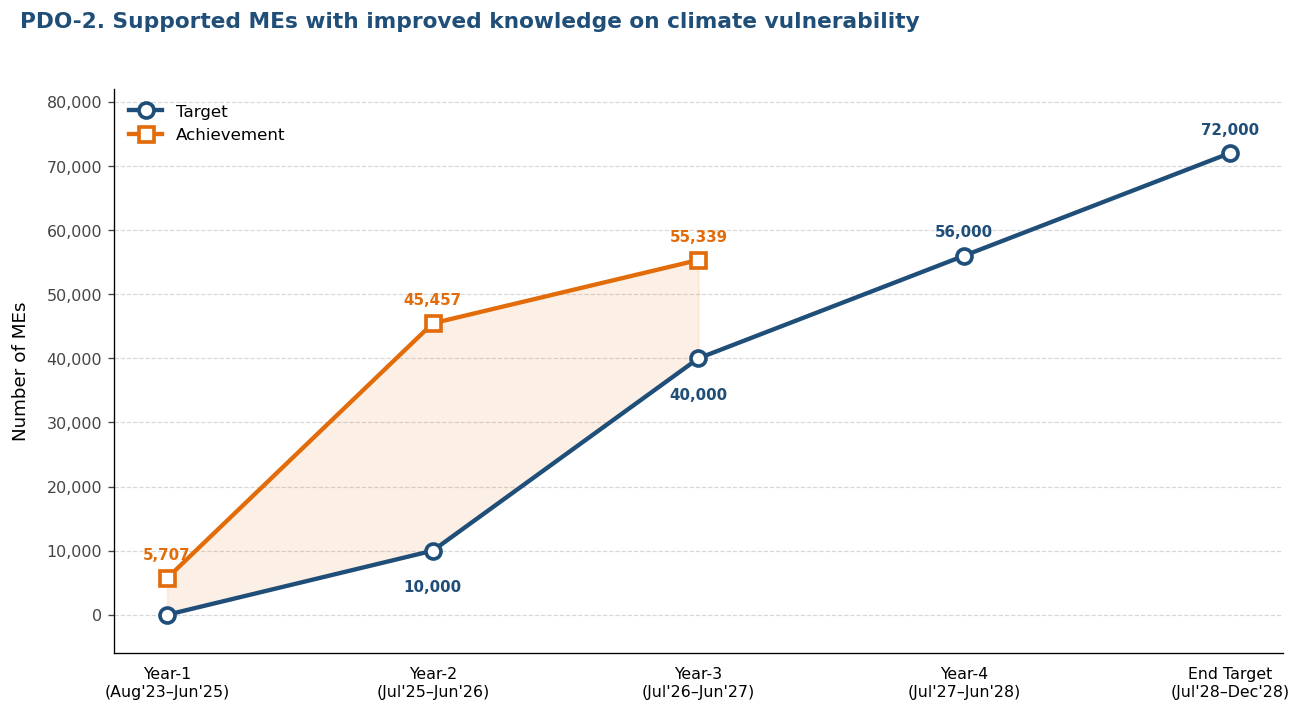

In [7]:
# PDO 2

years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 10000, 40000, 56000, 72000]
achievement = [5707, 45457, 55339, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Plot lines
# ------------------------------------------------------------------
ax.plot(years, target, marker="o", markersize=9, linewidth=2.6,
        color="#1f4e79", markerfacecolor="white", markeredgewidth=2.2,
        label="Target", zorder=3)

ax.plot(years, achievement, marker="s", markersize=9, linewidth=2.6,
        color="#E36C0A", markerfacecolor="white", markeredgewidth=2.2,
        label="Achievement", zorder=4)

# ------------------------------------------------------------------
# 4. Shade the gap (achievement vs target where both exist)
# ------------------------------------------------------------------
x = np.arange(len(years))
target_arr = np.array(target, dtype=float)
ach_arr    = np.array(achievement, dtype=float)
mask       = ~np.isnan(ach_arr)
ax.fill_between(x[mask], ach_arr[mask], target_arr[mask],
                color="#E36C0A", alpha=0.10, zorder=1)

# ------------------------------------------------------------------
# 5. Data labels
#    Year-1 (1):   target so tiny it would clutter → skipped
#    Year-1 ach:   "5,707" above the orange square
#    Year-2 ach:   "45,457" above the square
#    Year-2 tgt:   "10,000" below the circle (clear gap)
#    Year-3 ach:   "55,339" above the square
#    Year-3 tgt:   "40,000" below the circle (clear gap)
#    Year-4 / End: "56,000" / "72,000" above circle
# ------------------------------------------------------------------
def add_labels(values, color, default_xy, overrides=None, skip=None):
    overrides = overrides or {}
    skip = skip or set()
    for i, v in enumerate(values):
        if np.isnan(v) or i in skip:
            continue
        dx, dy, ha = overrides.get(i, default_xy)
        ax.annotate(f"{int(v):,}",
                    xy=(i, v), xytext=(dx, dy),
                    textcoords="offset points",
                    ha=ha, va="center",
                    fontsize=9, fontweight="bold", color=color)

# Achievement labels — all above the squares
add_labels(achievement, "#E36C0A", default_xy=(0, 14, "center"))

# Target labels — above by default; below for Year-2 & Year-3 to avoid clashes
add_labels(target, "#1f4e79", default_xy=(0, 14, "center"),
           overrides={1: (0, -22, "center"), 2: (0, -22, "center")},
           skip={0})   # hide Year-1 target label

# ------------------------------------------------------------------
# 6. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(-6000, 82000)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_ylabel("Number of MEs", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 7. Title & legend
# ------------------------------------------------------------------
fig.suptitle(
    "PDO-2. Supported MEs with improved knowledge on climate vulnerability",
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 8. Layout & save as JPG (robust)
# ------------------------------------------------------------------
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.canvas.draw()

plt.savefig("2. pdo 2_Improved knowledge on climate vulnerability.jpg", dpi=200, bbox_inches="tight")
plt.show()


# 3. IRI 1

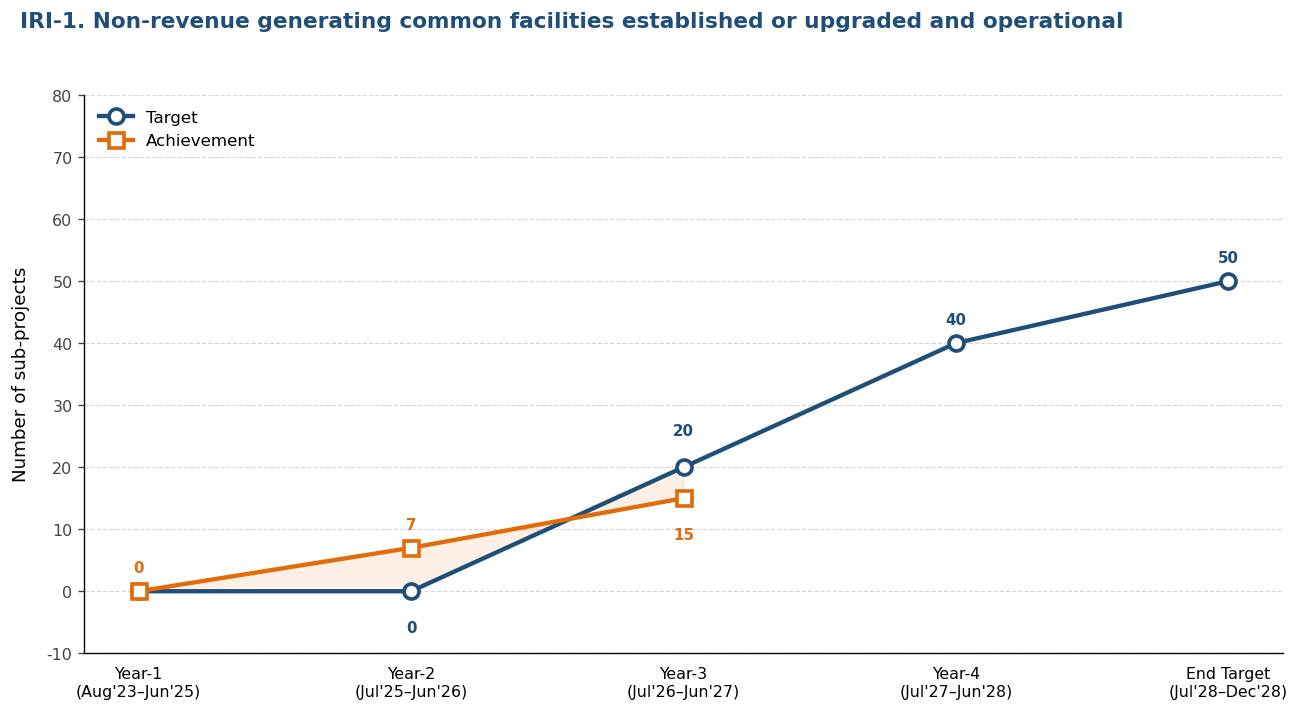

In [15]:
# IRI 1
# PDO 2

years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 0, 20, 40, 50]
achievement = [0, 7, 15, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Plot lines
# ------------------------------------------------------------------
ax.plot(years, target, marker="o", markersize=9, linewidth=2.6,
        color="#1f4e79", markerfacecolor="white", markeredgewidth=2.2,
        label="Target", zorder=3)

ax.plot(years, achievement, marker="s", markersize=9, linewidth=2.6,
        color="#E36C0A", markerfacecolor="white", markeredgewidth=2.2,
        label="Achievement", zorder=4)

# ------------------------------------------------------------------
# 4. Shade the gap (achievement vs target where both exist)
# ------------------------------------------------------------------
x = np.arange(len(years))
target_arr = np.array(target, dtype=float)
ach_arr    = np.array(achievement, dtype=float)
mask       = ~np.isnan(ach_arr)
ax.fill_between(x[mask], ach_arr[mask], target_arr[mask],
                color="#E36C0A", alpha=0.10, zorder=1)

# ------------------------------------------------------------------
# 5. Data labels
#    Year-1 (1):   target so tiny it would clutter → skipped
#    Year-1 ach:   "5,707" above the orange square
#    Year-2 ach:   "45,457" above the square
#    Year-2 tgt:   "10,000" below the circle (clear gap)
#    Year-3 ach:   "55,339" above the square
#    Year-3 tgt:   "40,000" below the circle (clear gap)
#    Year-4 / End: "56,000" / "72,000" above circle
# ------------------------------------------------------------------
def add_labels(values, color, default_xy, overrides=None, skip=None):
    overrides = overrides or {}
    skip = skip or set()
    for i, v in enumerate(values):
        if np.isnan(v) or i in skip:
            continue
        dx, dy, ha = overrides.get(i, default_xy)
        ax.annotate(f"{int(v):,}",
                    xy=(i, v), xytext=(dx, dy),
                    textcoords="offset points",
                    ha=ha, va="center",
                    fontsize=9, fontweight="bold", color=color)

# Achievement labels — all above the squares
add_labels(achievement, "#E36C0A", default_xy=(0, 14, "center"), overrides={2:(0, -22, "center")})

# Target labels — above by default; below for Year-2 & Year-3 to avoid clashes
add_labels(target, "#1f4e79", default_xy=(0, 14, "center"),
           overrides={1: (0, -22, "center"), 2: (0, 22, "center")},
           skip={0})   # hide Year-1 target label

# ------------------------------------------------------------------
# 6. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(-10, 80)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_ylabel("Number of sub-projects", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 7. Title & legend
# ------------------------------------------------------------------
fig.suptitle(
    "IRI-1. Non-revenue generating common facilities established or upgraded and operational",
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 8. Layout & save as JPG (robust)
# ------------------------------------------------------------------
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.canvas.draw()

plt.savefig("3. IRI-1 NRGCS.jpg", dpi=200, bbox_inches="tight")
plt.show()


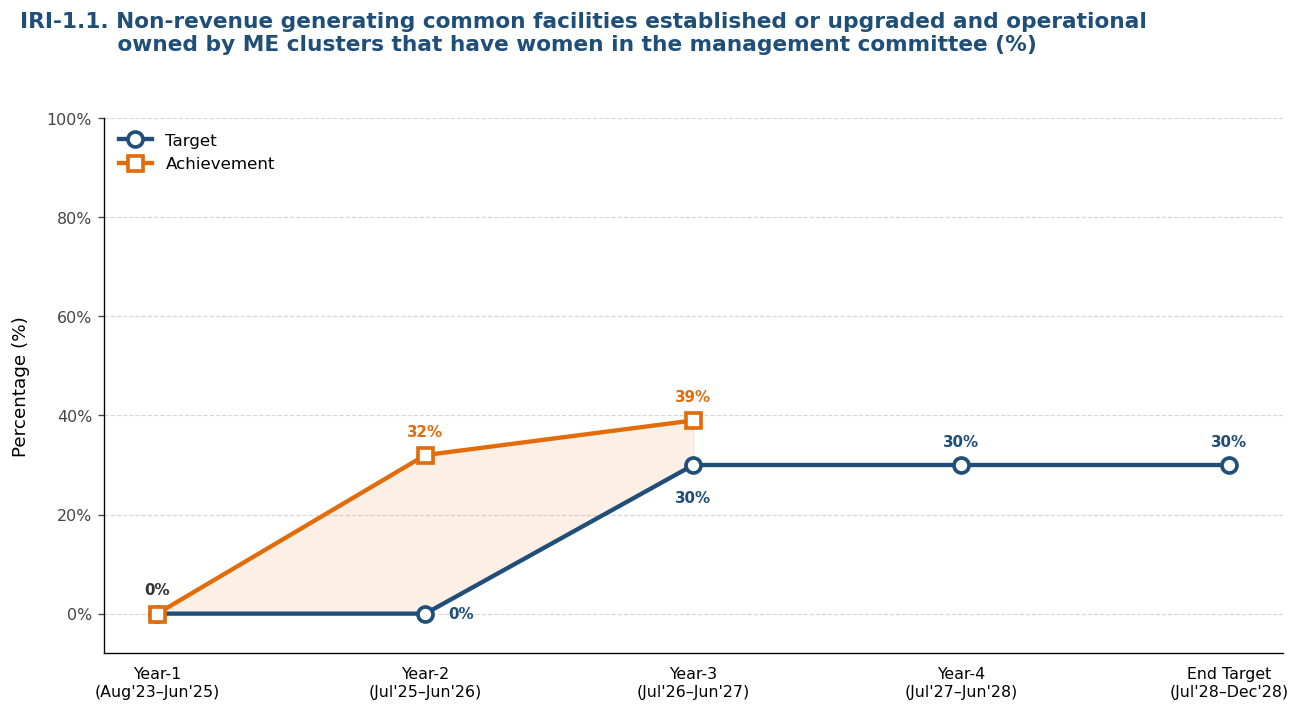

In [24]:
# IRI 1.1


# PDO 1.1
years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 0, 30, 30, 30]
achievement = [0, 32, 39, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Plot lines
# ------------------------------------------------------------------
ax.plot(years, target, marker="o", markersize=9, linewidth=2.6,
        color="#1f4e79", markerfacecolor="white", markeredgewidth=2.2,
        label="Target", zorder=3)

ax.plot(years, achievement, marker="s", markersize=9, linewidth=2.6,
        color="#E36C0A", markerfacecolor="white", markeredgewidth=2.2,
        label="Achievement", zorder=4)

# ------------------------------------------------------------------
# 4. Shade the gap (achievement vs target where both exist)
# ------------------------------------------------------------------
x = np.arange(len(years))
target_arr = np.array(target, dtype=float)
ach_arr    = np.array(achievement, dtype=float)
mask       = ~np.isnan(ach_arr)
ax.fill_between(x[mask], ach_arr[mask], target_arr[mask],
                color="#E36C0A", alpha=0.10, zorder=1)

# ------------------------------------------------------------------
# 5. Data labels
#    Year-1 (0): single shared "0%" above the point
#    Year-2 (1): achievement "81%" ABOVE the square
#                target "0%" to the RIGHT of the circle, on the line
#    Year-3 (2): both labels — achievement above, target below
#    Other years: default offsets
# ------------------------------------------------------------------
def add_labels(values, color, default_xy, overrides=None, skip=None):
    overrides = overrides or {}
    skip = skip or set()
    for i, v in enumerate(values):
        if np.isnan(v) or i in skip:
            continue
        dx, dy, ha = overrides.get(i, default_xy)
        ax.annotate(f"{int(v)}%",
                    xy=(i, v), xytext=(dx, dy),
                    textcoords="offset points",
                    ha=ha, va="center",
                    fontsize=9, fontweight="bold", color=color)

# Achievement labels
add_labels(achievement, "#E36C0A", default_xy=(0, 14, "center"),
           overrides={1: (0, 14, "center"),      # Year-2 → above square
                      2: (0, 14, "center")},     # Year-3 → above square
           skip={0})

# Target labels
add_labels(target, "#1f4e79", default_xy=(0, 14, "center"),
           overrides={1: (14, 0, "left"),        # Year-2 → right of circle, on line
                      2: (0, -20, "center"),     # Year-3 → below circle
                      3: (0, 14, "center"),      # Year-4 → above
                      4: (0, 14, "center")},     # End Target → above
           skip={0})

# Shared "0%" at Year-1 (both = 0)
ax.annotate("0%",
            xy=(0, 0), xytext=(0, 14),
            textcoords="offset points",
            ha="center", va="center",
            fontsize=9, fontweight="bold", color="#333333")

# ------------------------------------------------------------------
# 6. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(-8, 100)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v)}%"))
ax.set_ylabel("Percentage (%)", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 7. Title
# ------------------------------------------------------------------
fig.suptitle(
    "IRI-1.1. Non-revenue generating common facilities established or upgraded and operational\n             owned by ME clusters that have women in the management committee (%)",
    
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)

# ------------------------------------------------------------------
# 8. Legend
# ------------------------------------------------------------------
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 9. Layout & save
# ------------------------------------------------------------------
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("3a. IRI-1 NRGCS Female members in management.jpg", dpi=200, bbox_inches="tight")
plt.show()

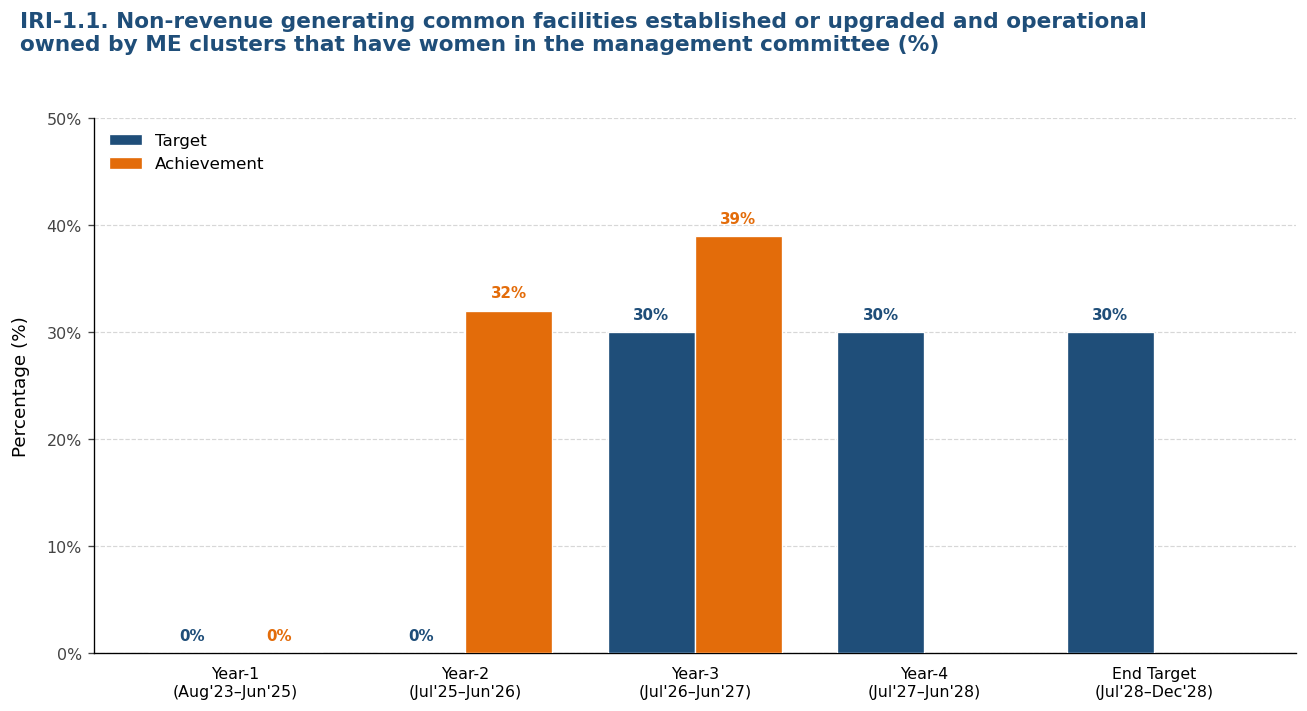

In [87]:
# IRI 1.1

years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 0, 30, 30, 30]
achievement = [0, 32, 39, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Grouped bars
# ------------------------------------------------------------------
x = np.arange(len(years))
bar_width = 0.38

target_plot = np.array([v if not np.isnan(v) else 0 for v in target], dtype=float)
ach_plot    = np.array([v if not np.isnan(v) else 0 for v in achievement], dtype=float)
ach_mask    = ~np.isnan(np.array(achievement, dtype=float))

bars_target = ax.bar(x - bar_width/2, target_plot, width=bar_width,
                     color="#1f4e79", edgecolor="white", linewidth=0.8,
                     label="Target", zorder=3)

bars_ach = ax.bar(x + bar_width/2, ach_plot, width=bar_width,
                  color="#E36C0A", edgecolor="white", linewidth=0.8,
                  label="Achievement", zorder=3)

# Hide ONLY the achievement bars with no data (Years 4 & End Target)
for i, bar in enumerate(bars_ach):
    if not ach_mask[i]:
        bar.set_visible(False)

# ------------------------------------------------------------------
# 4. Data labels — one per visible bar, no skipping, no shared label
# ------------------------------------------------------------------
def bar_labels(bars, values, color, formatter, visible_mask=None):
    for i, (bar, v) in enumerate(zip(bars, values)):
        if visible_mask is not None and not visible_mask[i]:
            continue
        h = bar.get_height()
        ax.annotate(formatter(v),
                    xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 6),
                    textcoords="offset points",
                    ha="center", va="bottom",
                    fontsize=9, fontweight="bold", color=color)

# Target labels — every bar gets a label (including Year-1 & Year-2 = 0%)
bar_labels(bars_target, target, "#1f4e79",
           formatter=lambda v: f"{int(v)}%")

# Achievement labels — only the visible bars (years with real data)
bar_labels(bars_ach, achievement, "#E36C0A",
           formatter=lambda v: f"{int(v)}%",
           visible_mask=ach_mask)

# ------------------------------------------------------------------
# 5. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(0, 50)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v)}%"))
ax.set_ylabel("Percentage (%)", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 6. Title
# ------------------------------------------------------------------
fig.suptitle(
    "IRI-1.1. Non-revenue generating common facilities established or upgraded and operational\n"
    "owned by ME clusters that have women in the management committee (%)",
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)

# ------------------------------------------------------------------
# 7. Legend
# ------------------------------------------------------------------
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 8. Layout & save
# ------------------------------------------------------------------
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("3aa. IRI-1 NRGCS Female members in management.jpg",
            dpi=200, bbox_inches="tight",
            facecolor="white", edgecolor="none",
            pil_kwargs={"quality": 95})
plt.show()

# 4. IRI 2

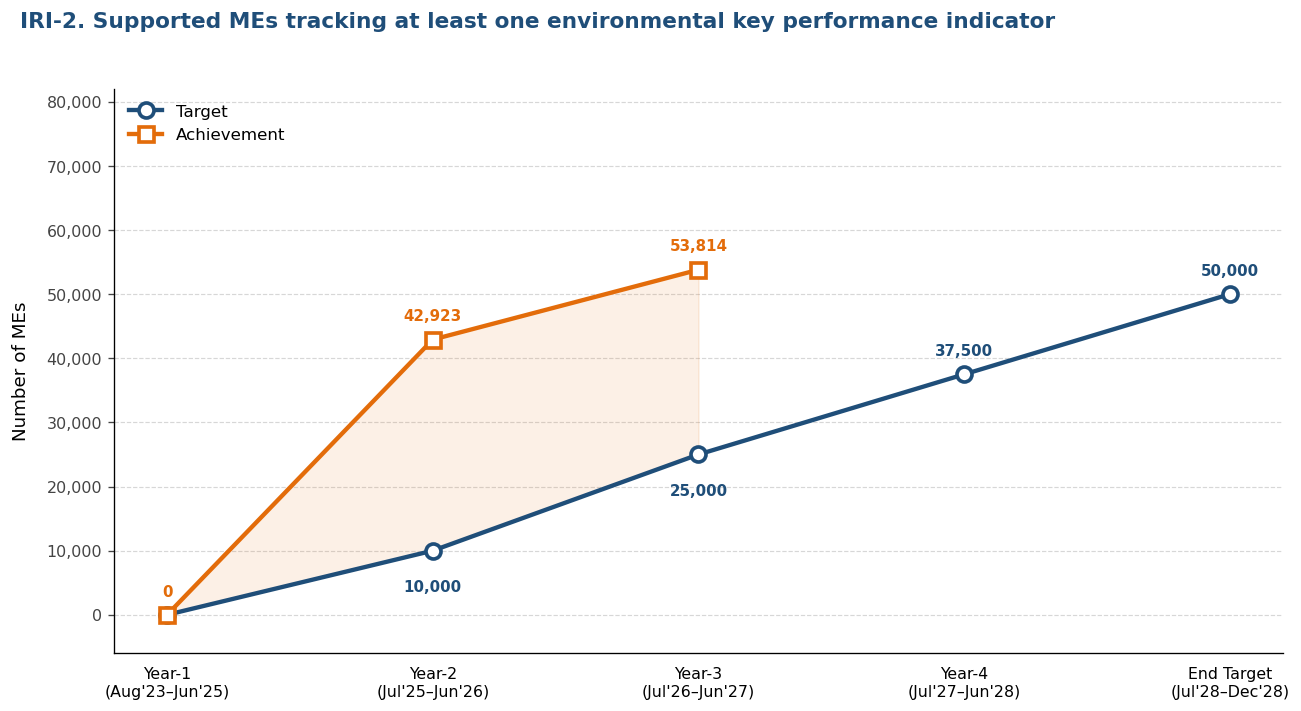

In [25]:
# IRI 2
# PDO 2

years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 10000, 25000, 37500, 50000]
achievement = [0, 42923, 53814, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Plot lines
# ------------------------------------------------------------------
ax.plot(years, target, marker="o", markersize=9, linewidth=2.6,
        color="#1f4e79", markerfacecolor="white", markeredgewidth=2.2,
        label="Target", zorder=3)

ax.plot(years, achievement, marker="s", markersize=9, linewidth=2.6,
        color="#E36C0A", markerfacecolor="white", markeredgewidth=2.2,
        label="Achievement", zorder=4)

# ------------------------------------------------------------------
# 4. Shade the gap (achievement vs target where both exist)
# ------------------------------------------------------------------
x = np.arange(len(years))
target_arr = np.array(target, dtype=float)
ach_arr    = np.array(achievement, dtype=float)
mask       = ~np.isnan(ach_arr)
ax.fill_between(x[mask], ach_arr[mask], target_arr[mask],
                color="#E36C0A", alpha=0.10, zorder=1)

# ------------------------------------------------------------------
# 5. Data labels
#    Year-1 (1):   target so tiny it would clutter → skipped
#    Year-1 ach:   "5,707" above the orange square
#    Year-2 ach:   "45,457" above the square
#    Year-2 tgt:   "10,000" below the circle (clear gap)
#    Year-3 ach:   "55,339" above the square
#    Year-3 tgt:   "40,000" below the circle (clear gap)
#    Year-4 / End: "56,000" / "72,000" above circle
# ------------------------------------------------------------------
def add_labels(values, color, default_xy, overrides=None, skip=None):
    overrides = overrides or {}
    skip = skip or set()
    for i, v in enumerate(values):
        if np.isnan(v) or i in skip:
            continue
        dx, dy, ha = overrides.get(i, default_xy)
        ax.annotate(f"{int(v):,}",
                    xy=(i, v), xytext=(dx, dy),
                    textcoords="offset points",
                    ha=ha, va="center",
                    fontsize=9, fontweight="bold", color=color)

# Achievement labels — all above the squares
add_labels(achievement, "#E36C0A", default_xy=(0, 14, "center"))

# Target labels — above by default; below for Year-2 & Year-3 to avoid clashes
add_labels(target, "#1f4e79", default_xy=(0, 14, "center"),
           overrides={1: (0, -22, "center"), 2: (0, -22, "center")},
           skip={0})   # hide Year-1 target label

# ------------------------------------------------------------------
# 6. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(-6000, 82000)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_ylabel("Number of MEs", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 7. Title & legend
# ------------------------------------------------------------------
fig.suptitle(
    "IRI-2. Supported MEs tracking at least one environmental key performance indicator",
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 8. Layout & save as JPG (robust)
# ------------------------------------------------------------------
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.canvas.draw()

plt.savefig("4. IRI 2_eKPI.jpg", dpi=200, bbox_inches="tight")
plt.show()


# 5. IRI 3

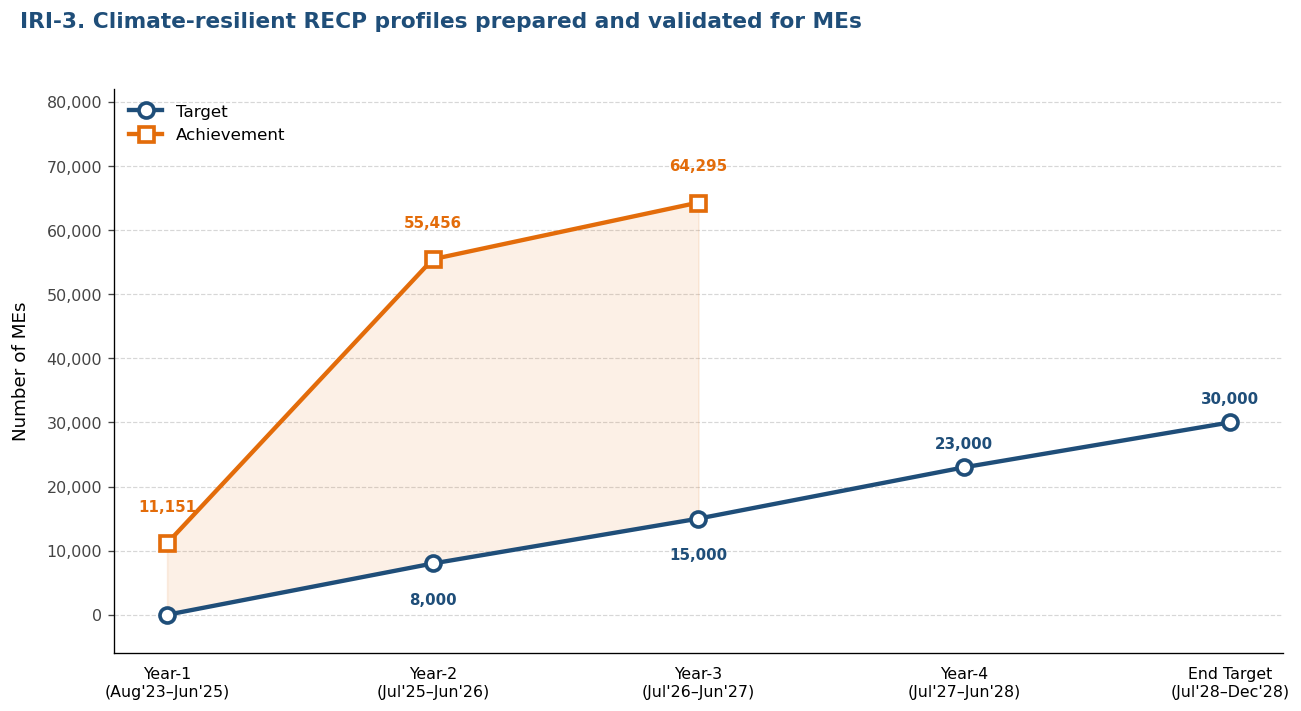

In [29]:
# IRI 3

years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 8000, 15000, 23000, 30000]
achievement = [11151, 55456, 64295, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Plot lines
# ------------------------------------------------------------------
ax.plot(years, target, marker="o", markersize=9, linewidth=2.6,
        color="#1f4e79", markerfacecolor="white", markeredgewidth=2.2,
        label="Target", zorder=3)

ax.plot(years, achievement, marker="s", markersize=9, linewidth=2.6,
        color="#E36C0A", markerfacecolor="white", markeredgewidth=2.2,
        label="Achievement", zorder=4)

# ------------------------------------------------------------------
# 4. Shade the gap (achievement vs target where both exist)
# ------------------------------------------------------------------
x = np.arange(len(years))
target_arr = np.array(target, dtype=float)
ach_arr    = np.array(achievement, dtype=float)
mask       = ~np.isnan(ach_arr)
ax.fill_between(x[mask], ach_arr[mask], target_arr[mask],
                color="#E36C0A", alpha=0.10, zorder=1)

# ------------------------------------------------------------------
# 5. Data labels
#    Year-1 (1):   target so tiny it would clutter → skipped
#    Year-1 ach:   "5,707" above the orange square
#    Year-2 ach:   "45,457" above the square
#    Year-2 tgt:   "10,000" below the circle (clear gap)
#    Year-3 ach:   "55,339" above the square
#    Year-3 tgt:   "40,000" below the circle (clear gap)
#    Year-4 / End: "56,000" / "72,000" above circle
# ------------------------------------------------------------------
def add_labels(values, color, default_xy, overrides=None, skip=None):
    overrides = overrides or {}
    skip = skip or set()
    for i, v in enumerate(values):
        if np.isnan(v) or i in skip:
            continue
        dx, dy, ha = overrides.get(i, default_xy)
        ax.annotate(f"{int(v):,}",
                    xy=(i, v), xytext=(dx, dy),
                    textcoords="offset points",
                    ha=ha, va="center",
                    fontsize=9, fontweight="bold", color=color)

# Achievement labels — all above the squares
add_labels(achievement, "#E36C0A", default_xy=(0, 22, "center"))

# Target labels — above by default; below for Year-2 & Year-3 to avoid clashes
add_labels(target, "#1f4e79", default_xy=(0, 14, "center"),
           overrides={1: (0, -22, "center"), 2: (0, -22, "center")},
           skip={0})   # hide Year-1 target label

# ------------------------------------------------------------------
# 6. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(-6000, 82000)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_ylabel("Number of MEs", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 7. Title & legend
# ------------------------------------------------------------------
fig.suptitle(
    "IRI-3. Climate-resilient RECP profiles prepared and validated for MEs",
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 8. Layout & save as JPG (robust)
# ------------------------------------------------------------------
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.canvas.draw()

plt.savefig("5. IRI 3_RECP Screening and profiling.jpg", dpi=200, bbox_inches="tight")
plt.show()


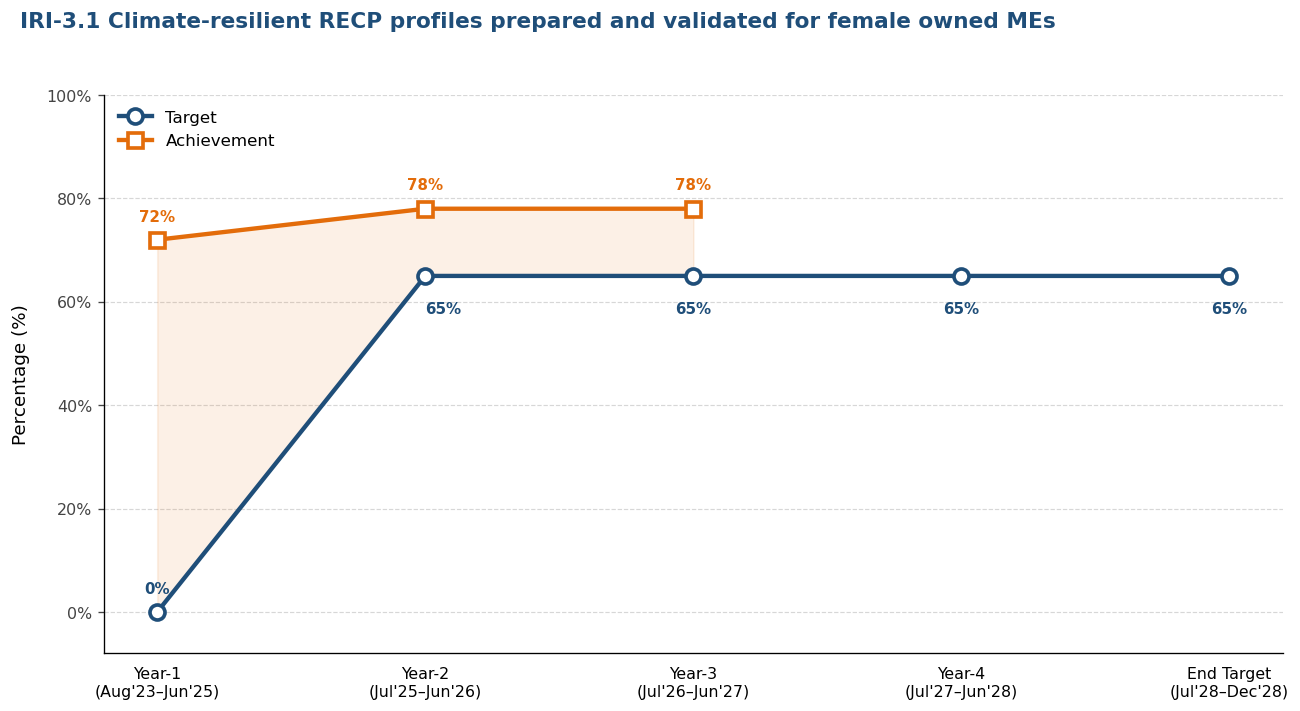

In [85]:
# IRI 3.1
years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 65, 65, 65, 65]
achievement = [72, 78, 78, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Plot lines
# ------------------------------------------------------------------
ax.plot(years, target, marker="o", markersize=9, linewidth=2.6,
        color="#1f4e79", markerfacecolor="white", markeredgewidth=2.2,
        label="Target", zorder=3)

ax.plot(years, achievement, marker="s", markersize=9, linewidth=2.6,
        color="#E36C0A", markerfacecolor="white", markeredgewidth=2.2,
        label="Achievement", zorder=4)

# ------------------------------------------------------------------
# 4. Shade the gap (achievement vs target where both exist)
# ------------------------------------------------------------------
x = np.arange(len(years))
target_arr = np.array(target, dtype=float)
ach_arr    = np.array(achievement, dtype=float)
mask       = ~np.isnan(ach_arr)
ax.fill_between(x[mask], ach_arr[mask], target_arr[mask],
                color="#E36C0A", alpha=0.10, zorder=1)

# ------------------------------------------------------------------
# 5. Data labels
#    Year-1 (0): single shared "0%" above the point
#    Year-2 (1): achievement "81%" ABOVE the square
#                target "0%" to the RIGHT of the circle, on the line
#    Year-3 (2): both labels — achievement above, target below
#    Other years: default offsets
# ------------------------------------------------------------------
def add_labels(values, color, default_xy, overrides=None, skip=None):
    overrides = overrides or {}
    skip = skip or set()
    for i, v in enumerate(values):
        if np.isnan(v) or i in skip:
            continue
        dx, dy, ha = overrides.get(i, default_xy)
        ax.annotate(f"{int(v)}%",
                    xy=(i, v), xytext=(dx, dy),
                    textcoords="offset points",
                    ha=ha, va="center",
                    fontsize=9, fontweight="bold", color=color)

# Achievement labels
add_labels(achievement, "#E36C0A", default_xy=(0, 14, "center"),
           overrides={0: (0, 14, "center"),
                    1: (0, 14, "center"),      # Year-2 → above square
                      2: (0, 14, "center")}     # Year-3 → above square
           )

# Target labels
add_labels(target, "#1f4e79", default_xy=(0, 14, "center"),
           overrides={1: (0, -20, "left"),        # Year-2 → right of circle, on line
                      2: (0, -20, "center"),     # Year-3 → below circle
                      3: (0, -20, "center"),      # Year-4 → above
                      4: (0, -20, "center")}     # End Target → above
           )



# ------------------------------------------------------------------
# 6. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(-8, 100)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v)}%"))
ax.set_ylabel("Percentage (%)", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 7. Title
# ------------------------------------------------------------------
fig.suptitle(
    "IRI-3.1 Climate-resilient RECP profiles prepared and validated for female owned MEs",
    
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)

# ------------------------------------------------------------------
# 8. Legend
# ------------------------------------------------------------------
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 9. Layout & save
# ------------------------------------------------------------------
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("5a. IRI-3.1 RECP screening for female ME.jpg", dpi=200, bbox_inches="tight")
plt.show()

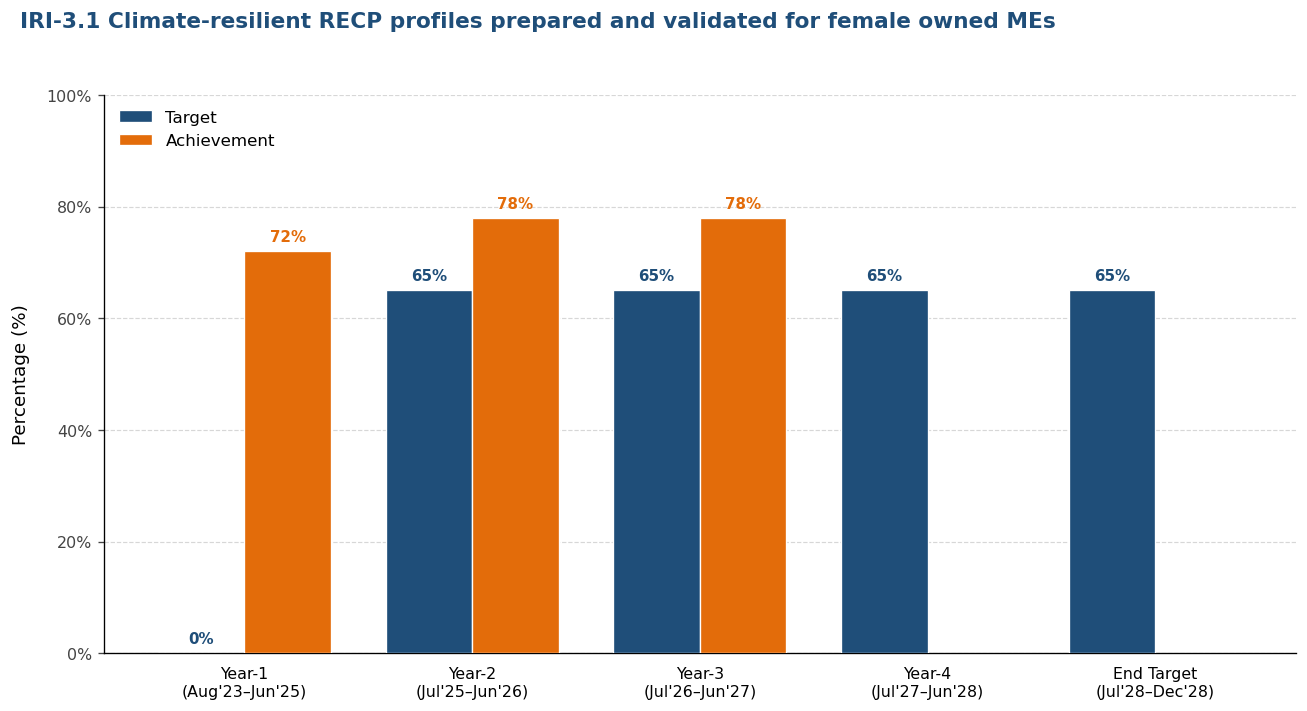

In [84]:
# IRI 3.1
years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 65, 65, 65, 65]
achievement = [72, 78, 78, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Grouped bars
# ------------------------------------------------------------------
x = np.arange(len(years))
bar_width = 0.38

target_plot = np.array([v if not np.isnan(v) else 0 for v in target], dtype=float)
ach_plot    = np.array([v if not np.isnan(v) else 0 for v in achievement], dtype=float)
ach_mask    = ~np.isnan(np.array(achievement, dtype=float))

bars_target = ax.bar(x - bar_width/2, target_plot, width=bar_width,
                     color="#1f4e79", edgecolor="white", linewidth=0.8,
                     label="Target", zorder=3)

bars_ach = ax.bar(x + bar_width/2, ach_plot, width=bar_width,
                  color="#E36C0A", edgecolor="white", linewidth=0.8,
                  label="Achievement", zorder=3)

# Hide ONLY the achievement bars with no data (Years 4 & End Target)
for i, bar in enumerate(bars_ach):
    if not ach_mask[i]:
        bar.set_visible(False)

# ------------------------------------------------------------------
# 4. Data labels — one per visible bar, no skipping, no shared label
# ------------------------------------------------------------------
def bar_labels(bars, values, color, formatter, visible_mask=None):
    for i, (bar, v) in enumerate(zip(bars, values)):
        if visible_mask is not None and not visible_mask[i]:
            continue
        h = bar.get_height()
        ax.annotate(formatter(v),
                    xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha="center", va="bottom",
                    fontsize=9, fontweight="bold", color=color)

# Target labels — every bar gets a label (including Year-1 = 0%)
bar_labels(bars_target, target, "#1f4e79",
           formatter=lambda v: f"{int(v)}%")

# Achievement labels — only the visible bars (years with real data)
bar_labels(bars_ach, achievement, "#E36C0A",
           formatter=lambda v: f"{int(v)}%",
           visible_mask=ach_mask)

# ------------------------------------------------------------------
# 5. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v)}%"))
ax.set_ylabel("Percentage (%)", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 6. Title
# ------------------------------------------------------------------
fig.suptitle(
    "IRI-3.1 Climate-resilient RECP profiles prepared and validated for female owned MEs",
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)

# ------------------------------------------------------------------
# 7. Legend
# ------------------------------------------------------------------
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 8. Layout & save
# ------------------------------------------------------------------
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("5aa. IRI-3.1 RECP screening for female ME.jpg",
            dpi=200, bbox_inches="tight",
            facecolor="white", edgecolor="none",
            pil_kwargs={"quality": 95})
plt.show()

# 6. IRI 4 Loans provided to MEs

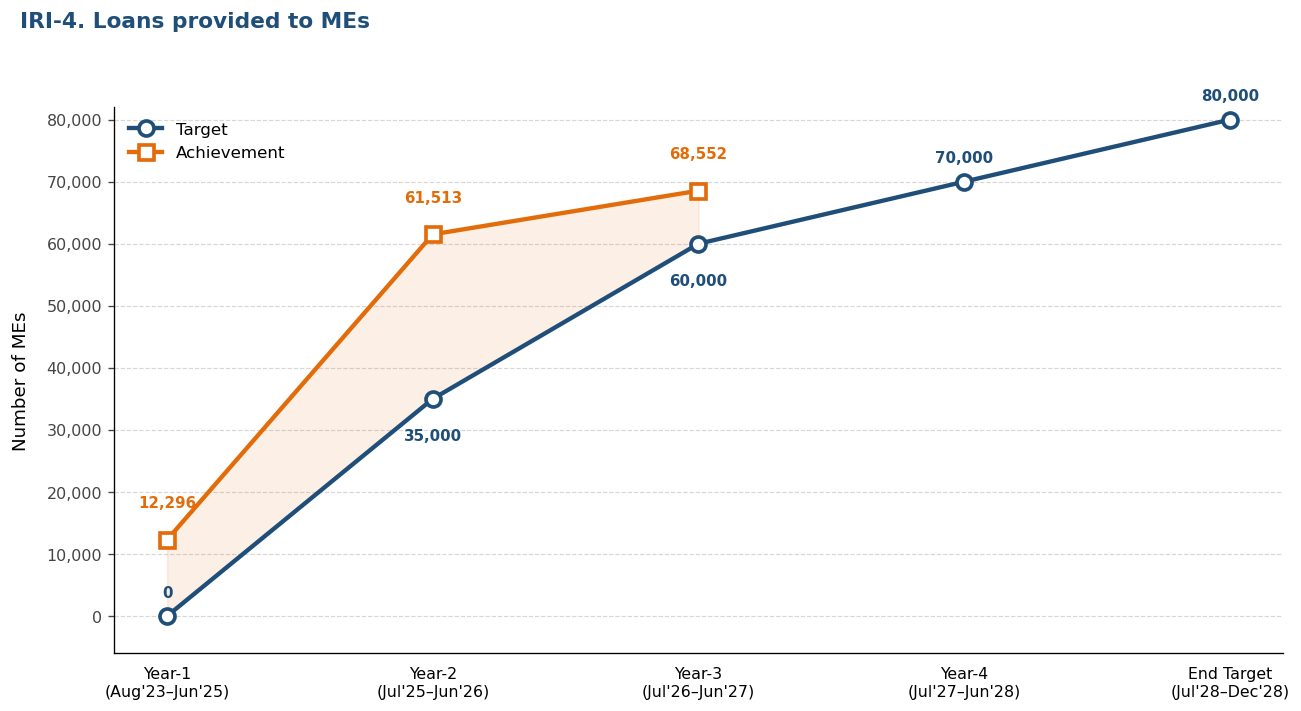

In [42]:
# IRI 4

years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 35000, 60000, 70000, 80000]
achievement = [12296, 61513, 68552, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Plot lines
# ------------------------------------------------------------------
ax.plot(years, target, marker="o", markersize=9, linewidth=2.6,
        color="#1f4e79", markerfacecolor="white", markeredgewidth=2.2,
        label="Target", zorder=3)

ax.plot(years, achievement, marker="s", markersize=9, linewidth=2.6,
        color="#E36C0A", markerfacecolor="white", markeredgewidth=2.2,
        label="Achievement", zorder=4)

# ------------------------------------------------------------------
# 4. Shade the gap (achievement vs target where both exist)
# ------------------------------------------------------------------
x = np.arange(len(years))
target_arr = np.array(target, dtype=float)
ach_arr    = np.array(achievement, dtype=float)
mask       = ~np.isnan(ach_arr)
ax.fill_between(x[mask], ach_arr[mask], target_arr[mask],
                color="#E36C0A", alpha=0.10, zorder=1)

# ------------------------------------------------------------------
# 5. Data labels
#    Year-1 (1):   target so tiny it would clutter → skipped
#    Year-1 ach:   "5,707" above the orange square
#    Year-2 ach:   "45,457" above the square
#    Year-2 tgt:   "10,000" below the circle (clear gap)
#    Year-3 ach:   "55,339" above the square
#    Year-3 tgt:   "40,000" below the circle (clear gap)
#    Year-4 / End: "56,000" / "72,000" above circle
# ------------------------------------------------------------------
def add_labels(values, color, default_xy, overrides=None, skip=None):
    overrides = overrides or {}
    skip = skip or set()
    for i, v in enumerate(values):
        if np.isnan(v) or i in skip:
            continue
        dx, dy, ha = overrides.get(i, default_xy)
        ax.annotate(f"{int(v):,}",
                    xy=(i, v), xytext=(dx, dy),
                    textcoords="offset points",
                    ha=ha, va="center",
                    fontsize=9, fontweight="bold", color=color)

# Achievement labels — all above the squares
add_labels(achievement, "#E36C0A", default_xy=(0, 22, "center"))

# Target labels — above by default; below for Year-2 & Year-3 to avoid clashes
add_labels(target, "#1f4e79", default_xy=(0, 14, "center"),
           overrides={1: (0, -22, "center"), 2: (0, -22, "center")}
           )   # hide Year-1 target label

# ------------------------------------------------------------------
# 6. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(-6000, 82000)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_ylabel("Number of MEs", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 7. Title & legend
# ------------------------------------------------------------------
fig.suptitle(
    "IRI-4. Loans provided to MEs",
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 8. Layout & save as JPG (robust)
# ------------------------------------------------------------------
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.canvas.draw()

plt.savefig("6. IRI 4_Number of MEs.jpg", dpi=200, bbox_inches="tight")
plt.show()


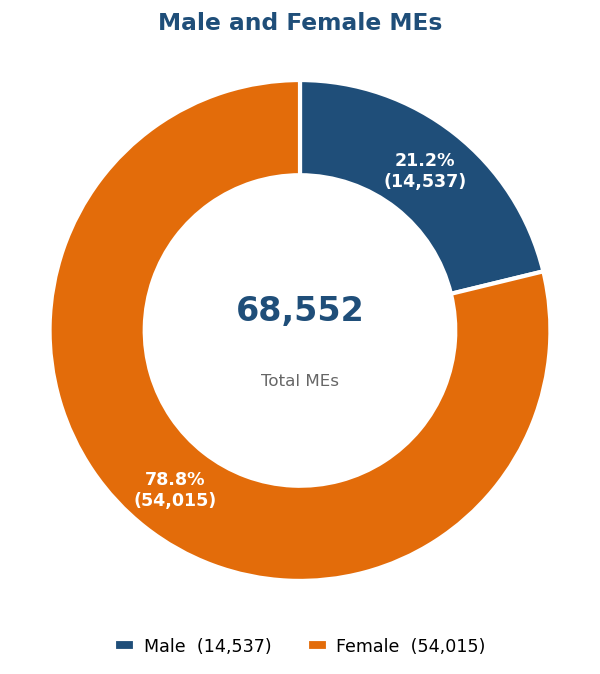

In [74]:
# ------------------------------------------------------------------
# 1. Data
# ------------------------------------------------------------------
labels = ["Male", "Female"]
values = [14537, 54015]
colors = ["#1f4e79", "#E36C0A"]
total  = sum(values)

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({"font.family": "DejaVu Sans"})

fig, ax = plt.subplots(figsize=(7, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Donut chart
# ------------------------------------------------------------------
wedges, _ = ax.pie(
    values,
    colors=colors,
    startangle=90,
    counterclock=False,
    wedgeprops=dict(width=0.38, edgecolor="white", linewidth=2.5),
    radius=1.0,
    center=(0, 0),
)

# ------------------------------------------------------------------
# 4. Labels on wedges
# ------------------------------------------------------------------
for w, v in zip(wedges, values):
    ang   = np.deg2rad((w.theta2 + w.theta1) / 2)
    r_lbl = 0.81
    xpos  = r_lbl * np.cos(ang)
    ypos  = r_lbl * np.sin(ang)
    pct   = v / total * 100
    ax.text(xpos, ypos,
            f"{pct:.1f}%\n({v:,})",
            ha="center", va="center",
            fontsize=10.5, fontweight="bold",
            color="white")

# ------------------------------------------------------------------
# 5. Centre text
# ------------------------------------------------------------------
ax.text(0, 0.08, f"{total:,}",
        ha="center", va="center",
        fontsize=20, fontweight="bold", color="#1f4e79")
ax.text(0, -0.20, "Total MEs",
        ha="center", va="center",
        fontsize=10, color="#666666")

# ------------------------------------------------------------------
# 6. Title
# ------------------------------------------------------------------
ax.set_title("Male and Female MEs",
             fontsize=14, fontweight="bold", color="#1f4e79",
             pad=8)

# ------------------------------------------------------------------
# 7. Legend — BELOW the donut, centered, side-by-side
# ------------------------------------------------------------------
ax.legend(
    wedges, [f"{l}  ({v:,})" for l, v in zip(labels, values)],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),   # below the axes, centred horizontally
    ncol=2,                        # Male | Female side-by-side
    frameon=False,
    fontsize=10.5,
    handlelength=1.2,
    handletextpad=0.5,
    columnspacing=2.0,
    borderaxespad=0.0,
)

# ------------------------------------------------------------------
# 8. Layout & save
# ------------------------------------------------------------------
ax.set_aspect("equal")
ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)

# Leave extra room at the bottom for the legend
fig.subplots_adjust(left=0.02, right=0.98, top=0.92, bottom=0.12)

fig.canvas.draw()
plt.savefig("6a. IRI 4a_Number of MEs by gender.jpg",
            dpi=200, bbox_inches="tight", pad_inches=0.05)
plt.show()

# 7. IRI 5

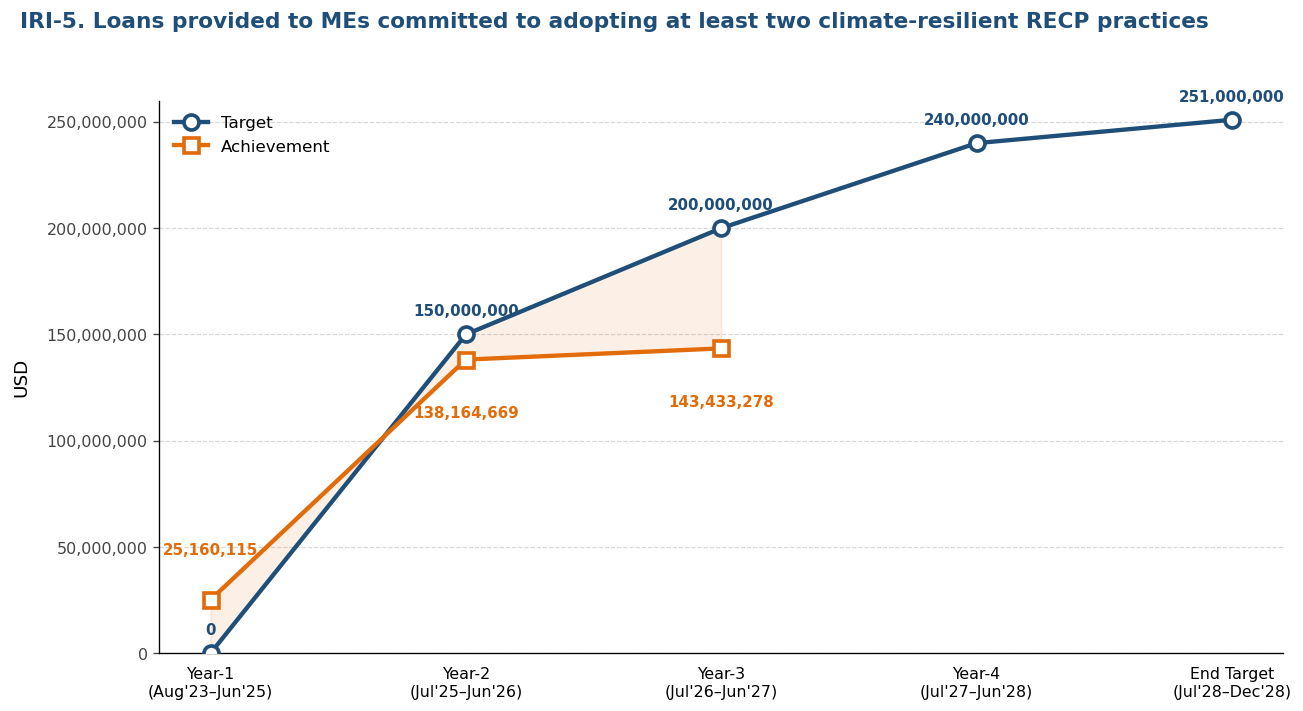

In [46]:
# IRI 5

years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 150000000, 200000000, 240000000, 251000000]
achievement = [25160115, 138164669, 143433278, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Plot lines
# ------------------------------------------------------------------
ax.plot(years, target, marker="o", markersize=9, linewidth=2.6,
        color="#1f4e79", markerfacecolor="white", markeredgewidth=2.2,
        label="Target", zorder=3)

ax.plot(years, achievement, marker="s", markersize=9, linewidth=2.6,
        color="#E36C0A", markerfacecolor="white", markeredgewidth=2.2,
        label="Achievement", zorder=4)

# ------------------------------------------------------------------
# 4. Shade the gap (achievement vs target where both exist)
# ------------------------------------------------------------------
x = np.arange(len(years))
target_arr = np.array(target, dtype=float)
ach_arr    = np.array(achievement, dtype=float)
mask       = ~np.isnan(ach_arr)
ax.fill_between(x[mask], ach_arr[mask], target_arr[mask],
                color="#E36C0A", alpha=0.10, zorder=1)

# ------------------------------------------------------------------
# 5. Data labels
#    Year-1 (1):   target so tiny it would clutter → skipped
#    Year-1 ach:   "5,707" above the orange square
#    Year-2 ach:   "45,457" above the square
#    Year-2 tgt:   "10,000" below the circle (clear gap)
#    Year-3 ach:   "55,339" above the square
#    Year-3 tgt:   "40,000" below the circle (clear gap)
#    Year-4 / End: "56,000" / "72,000" above circle
# ------------------------------------------------------------------
def add_labels(values, color, default_xy, overrides=None, skip=None):
    overrides = overrides or {}
    skip = skip or set()
    for i, v in enumerate(values):
        if np.isnan(v) or i in skip:
            continue
        dx, dy, ha = overrides.get(i, default_xy)
        ax.annotate(f"{int(v):,}",
                    xy=(i, v), xytext=(dx, dy),
                    textcoords="offset points",
                    ha=ha, va="center",
                    fontsize=9, fontweight="bold", color=color)

# Achievement labels — all above the squares
add_labels(achievement, "#E36C0A", default_xy=(0, -32, "center"),
           overrides={0: (0, 30, "center")})

# Target labels — above by default; below for Year-2 & Year-3 to avoid clashes
add_labels(target, "#1f4e79", default_xy=(0, 14, "center")
           )   

# ------------------------------------------------------------------
# 6. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(-6000, 260000000)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_ylabel("USD", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 7. Title & legend
# ------------------------------------------------------------------
fig.suptitle(
    "IRI-5. Loans provided to MEs committed to adopting at least two climate-resilient RECP practices",
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 8. Layout & save as JPG (robust)
# ------------------------------------------------------------------
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.canvas.draw()

plt.savefig("7. IRI 5_Loan amount.jpg", dpi=200, bbox_inches="tight")
plt.show()


# 8. IRI 6: RGCS

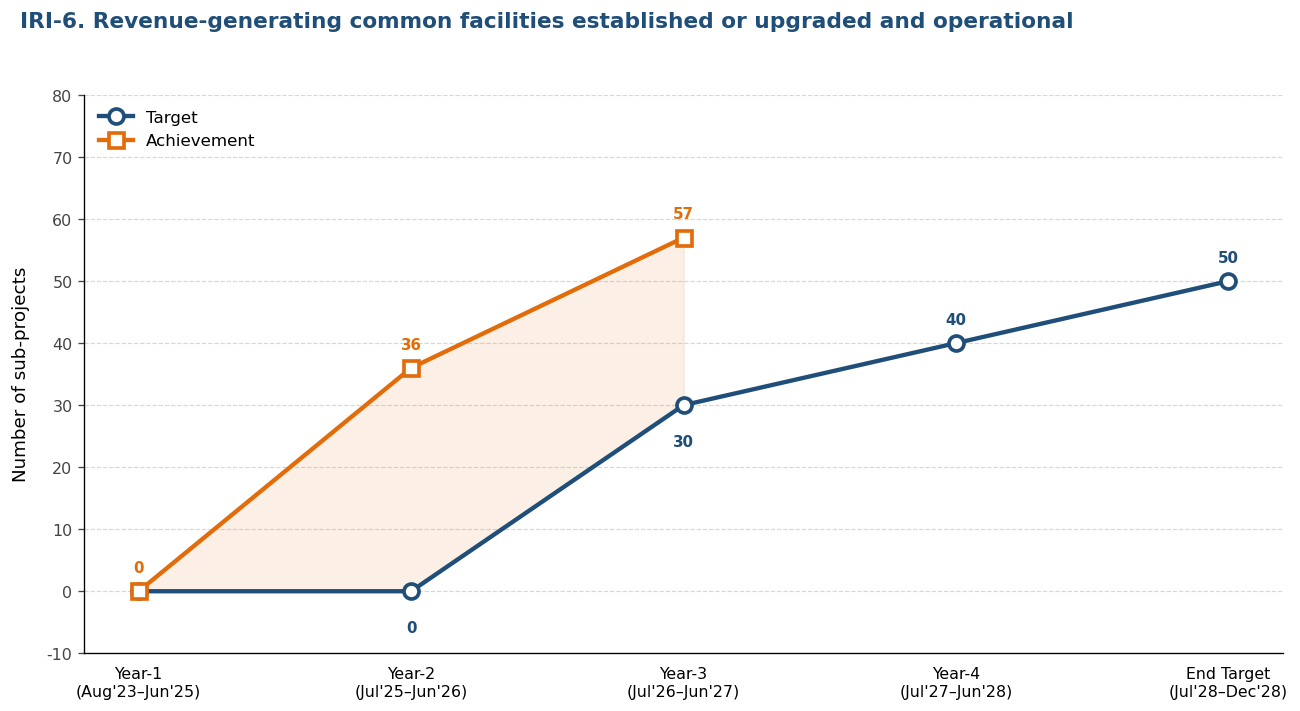

In [48]:
# IRI 6

years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 0, 30, 40, 50]
achievement = [0, 36, 57, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Plot lines
# ------------------------------------------------------------------
ax.plot(years, target, marker="o", markersize=9, linewidth=2.6,
        color="#1f4e79", markerfacecolor="white", markeredgewidth=2.2,
        label="Target", zorder=3)

ax.plot(years, achievement, marker="s", markersize=9, linewidth=2.6,
        color="#E36C0A", markerfacecolor="white", markeredgewidth=2.2,
        label="Achievement", zorder=4)

# ------------------------------------------------------------------
# 4. Shade the gap (achievement vs target where both exist)
# ------------------------------------------------------------------
x = np.arange(len(years))
target_arr = np.array(target, dtype=float)
ach_arr    = np.array(achievement, dtype=float)
mask       = ~np.isnan(ach_arr)
ax.fill_between(x[mask], ach_arr[mask], target_arr[mask],
                color="#E36C0A", alpha=0.10, zorder=1)

# ------------------------------------------------------------------
# 5. Data labels
#    Year-1 (1):   target so tiny it would clutter → skipped
#    Year-1 ach:   "5,707" above the orange square
#    Year-2 ach:   "45,457" above the square
#    Year-2 tgt:   "10,000" below the circle (clear gap)
#    Year-3 ach:   "55,339" above the square
#    Year-3 tgt:   "40,000" below the circle (clear gap)
#    Year-4 / End: "56,000" / "72,000" above circle
# ------------------------------------------------------------------
def add_labels(values, color, default_xy, overrides=None, skip=None):
    overrides = overrides or {}
    skip = skip or set()
    for i, v in enumerate(values):
        if np.isnan(v) or i in skip:
            continue
        dx, dy, ha = overrides.get(i, default_xy)
        ax.annotate(f"{int(v):,}",
                    xy=(i, v), xytext=(dx, dy),
                    textcoords="offset points",
                    ha=ha, va="center",
                    fontsize=9, fontweight="bold", color=color)

# Achievement labels — all above the squares
add_labels(achievement, "#E36C0A", default_xy=(0, 14, "center"))

# Target labels — above by default; below for Year-2 & Year-3 to avoid clashes
add_labels(target, "#1f4e79", default_xy=(0, 14, "center"),
           overrides={1: (0, -22, "center"), 2: (0, -22, "center")},
           skip={0})   # hide Year-1 target label

# ------------------------------------------------------------------
# 6. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(-10, 80)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_ylabel("Number of sub-projects", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 7. Title & legend
# ------------------------------------------------------------------
fig.suptitle(
    "IRI-6. Revenue-generating common facilities established or upgraded and operational",
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 8. Layout & save as JPG (robust)
# ------------------------------------------------------------------
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.canvas.draw()

plt.savefig("8. IRI-6 RGCS.jpg", dpi=200, bbox_inches="tight")
plt.show()


# 9. IRI 7 ECCU

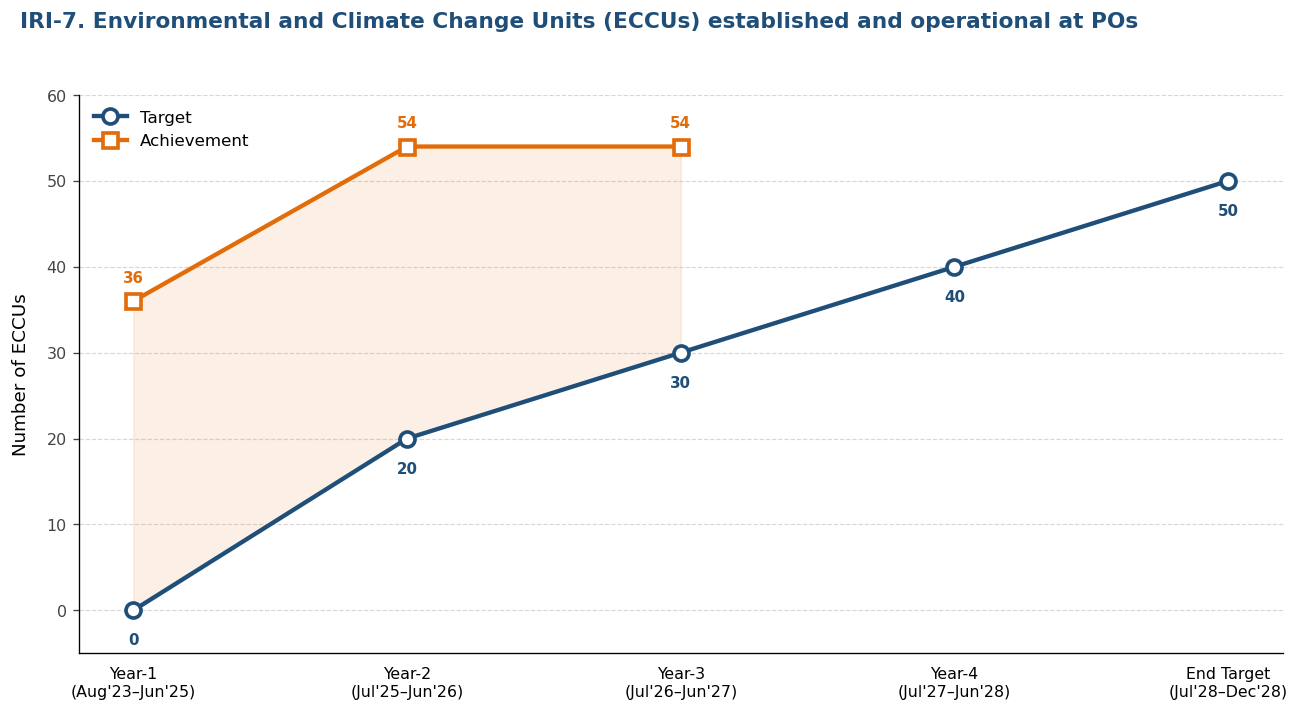

In [54]:
# IRI 7

years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 20, 30, 40, 50]
achievement = [36, 54, 54, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Plot lines
# ------------------------------------------------------------------
ax.plot(years, target, marker="o", markersize=9, linewidth=2.6,
        color="#1f4e79", markerfacecolor="white", markeredgewidth=2.2,
        label="Target", zorder=3)

ax.plot(years, achievement, marker="s", markersize=9, linewidth=2.6,
        color="#E36C0A", markerfacecolor="white", markeredgewidth=2.2,
        label="Achievement", zorder=4)

# ------------------------------------------------------------------
# 4. Shade the gap (achievement vs target where both exist)
# ------------------------------------------------------------------
x = np.arange(len(years))
target_arr = np.array(target, dtype=float)
ach_arr    = np.array(achievement, dtype=float)
mask       = ~np.isnan(ach_arr)
ax.fill_between(x[mask], ach_arr[mask], target_arr[mask],
                color="#E36C0A", alpha=0.10, zorder=1)

# ------------------------------------------------------------------
# 5. Data labels
#    Year-1 (1):   target so tiny it would clutter → skipped
#    Year-1 ach:   "5,707" above the orange square
#    Year-2 ach:   "45,457" above the square
#    Year-2 tgt:   "10,000" below the circle (clear gap)
#    Year-3 ach:   "55,339" above the square
#    Year-3 tgt:   "40,000" below the circle (clear gap)
#    Year-4 / End: "56,000" / "72,000" above circle
# ------------------------------------------------------------------
def add_labels(values, color, default_xy, overrides=None, skip=None):
    overrides = overrides or {}
    skip = skip or set()
    for i, v in enumerate(values):
        if np.isnan(v) or i in skip:
            continue
        dx, dy, ha = overrides.get(i, default_xy)
        ax.annotate(f"{int(v):,}",
                    xy=(i, v), xytext=(dx, dy),
                    textcoords="offset points",
                    ha=ha, va="center",
                    fontsize=9, fontweight="bold", color=color)

# Achievement labels — all above the squares
add_labels(achievement, "#E36C0A", default_xy=(0, 14, "center"))

# Target labels — above by default; below for Year-2 & Year-3 to avoid clashes
add_labels(target, "#1f4e79", default_xy=(0, -18, "center"),
           
           )   # hide Year-1 target label

# ------------------------------------------------------------------
# 6. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(-5, 60)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_ylabel("Number of ECCUs", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 7. Title & legend
# ------------------------------------------------------------------
fig.suptitle(
    "IRI-7. Environmental and Climate Change Units (ECCUs) established and operational at POs",
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 8. Layout & save as JPG (robust)
# ------------------------------------------------------------------
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.canvas.draw()

plt.savefig("9. IRI-7 ECCU.jpg", dpi=200, bbox_inches="tight")
plt.show()


# 10. IRI 8 EC

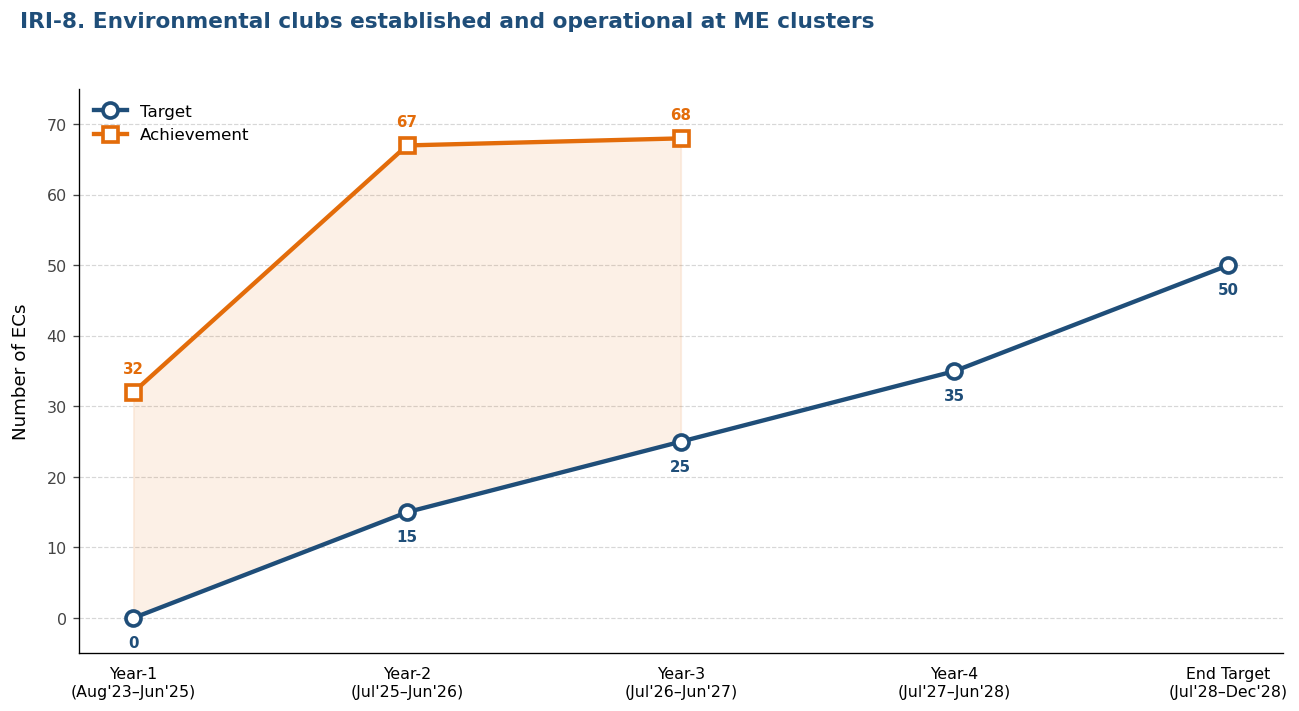

In [57]:
# IRI 8

years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 15, 25, 35, 50]
achievement = [32, 67, 68, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Plot lines
# ------------------------------------------------------------------
ax.plot(years, target, marker="o", markersize=9, linewidth=2.6,
        color="#1f4e79", markerfacecolor="white", markeredgewidth=2.2,
        label="Target", zorder=3)

ax.plot(years, achievement, marker="s", markersize=9, linewidth=2.6,
        color="#E36C0A", markerfacecolor="white", markeredgewidth=2.2,
        label="Achievement", zorder=4)

# ------------------------------------------------------------------
# 4. Shade the gap (achievement vs target where both exist)
# ------------------------------------------------------------------
x = np.arange(len(years))
target_arr = np.array(target, dtype=float)
ach_arr    = np.array(achievement, dtype=float)
mask       = ~np.isnan(ach_arr)
ax.fill_between(x[mask], ach_arr[mask], target_arr[mask],
                color="#E36C0A", alpha=0.10, zorder=1)

# ------------------------------------------------------------------
# 5. Data labels
#    Year-1 (1):   target so tiny it would clutter → skipped
#    Year-1 ach:   "5,707" above the orange square
#    Year-2 ach:   "45,457" above the square
#    Year-2 tgt:   "10,000" below the circle (clear gap)
#    Year-3 ach:   "55,339" above the square
#    Year-3 tgt:   "40,000" below the circle (clear gap)
#    Year-4 / End: "56,000" / "72,000" above circle
# ------------------------------------------------------------------
def add_labels(values, color, default_xy, overrides=None, skip=None):
    overrides = overrides or {}
    skip = skip or set()
    for i, v in enumerate(values):
        if np.isnan(v) or i in skip:
            continue
        dx, dy, ha = overrides.get(i, default_xy)
        ax.annotate(f"{int(v):,}",
                    xy=(i, v), xytext=(dx, dy),
                    textcoords="offset points",
                    ha=ha, va="center",
                    fontsize=9, fontweight="bold", color=color)

# Achievement labels — all above the squares
add_labels(achievement, "#E36C0A", default_xy=(0, 14, "center"))

# Target labels — above by default; below for Year-2 & Year-3 to avoid clashes
add_labels(target, "#1f4e79", default_xy=(0, -15, "center"),
           
           )   # hide Year-1 target label

# ------------------------------------------------------------------
# 6. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(-5, 75)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_ylabel("Number of ECs", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 7. Title & legend
# ------------------------------------------------------------------
fig.suptitle(
    "IRI-8. Environmental clubs established and operational at ME clusters",
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 8. Layout & save as JPG (robust)
# ------------------------------------------------------------------
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.canvas.draw()

plt.savefig("10. IRI-8 EC.jpg", dpi=200, bbox_inches="tight")
plt.show()


# 11. IRI 9- Grievance

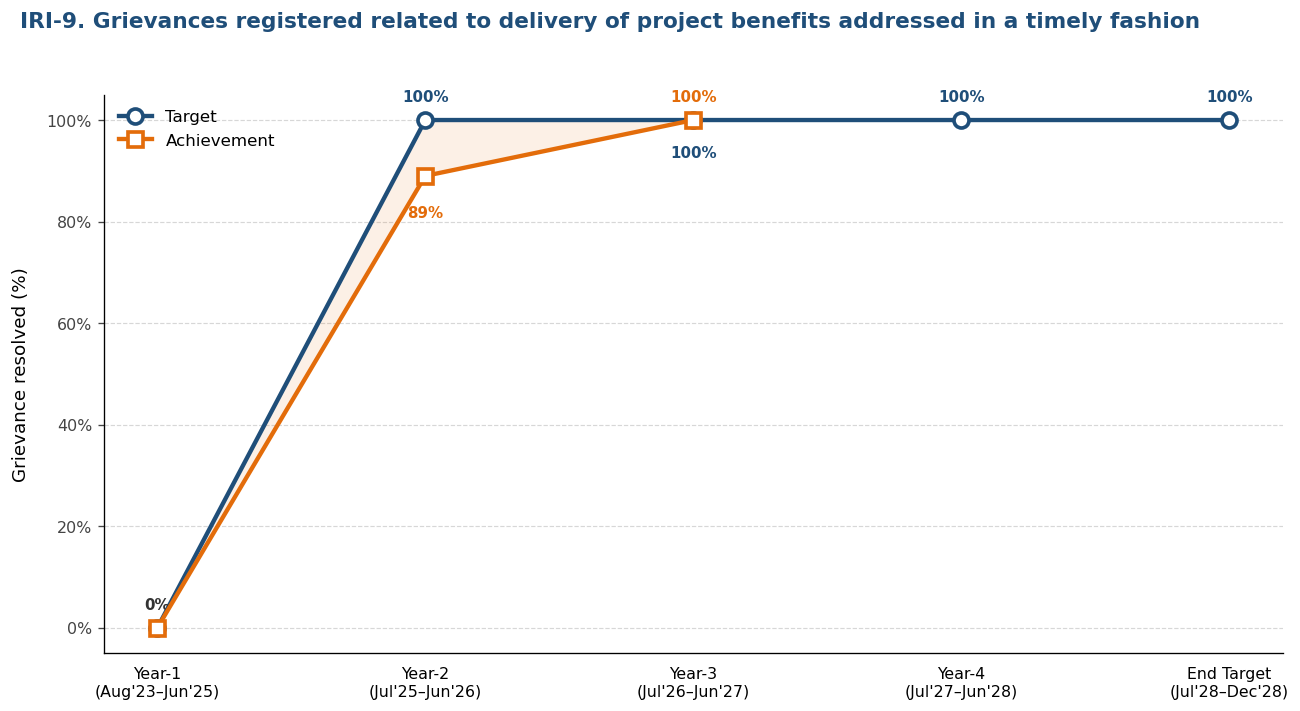

In [66]:
# IRI 9


# PDO 1.1
years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 100, 100, 100, 100]
achievement = [0, 89, 100, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Plot lines
# ------------------------------------------------------------------
ax.plot(years, target, marker="o", markersize=9, linewidth=2.6,
        color="#1f4e79", markerfacecolor="white", markeredgewidth=2.2,
        label="Target", zorder=3)

ax.plot(years, achievement, marker="s", markersize=9, linewidth=2.6,
        color="#E36C0A", markerfacecolor="white", markeredgewidth=2.2,
        label="Achievement", zorder=4)

# ------------------------------------------------------------------
# 4. Shade the gap (achievement vs target where both exist)
# ------------------------------------------------------------------
x = np.arange(len(years))
target_arr = np.array(target, dtype=float)
ach_arr    = np.array(achievement, dtype=float)
mask       = ~np.isnan(ach_arr)
ax.fill_between(x[mask], ach_arr[mask], target_arr[mask],
                color="#E36C0A", alpha=0.10, zorder=1)

# ------------------------------------------------------------------
# 5. Data labels
#    Year-1 (0): single shared "0%" above the point
#    Year-2 (1): achievement "81%" ABOVE the square
#                target "0%" to the RIGHT of the circle, on the line
#    Year-3 (2): both labels — achievement above, target below
#    Other years: default offsets
# ------------------------------------------------------------------
def add_labels(values, color, default_xy, overrides=None, skip=None):
    overrides = overrides or {}
    skip = skip or set()
    for i, v in enumerate(values):
        if np.isnan(v) or i in skip:
            continue
        dx, dy, ha = overrides.get(i, default_xy)
        ax.annotate(f"{int(v)}%",
                    xy=(i, v), xytext=(dx, dy),
                    textcoords="offset points",
                    ha=ha, va="center",
                    fontsize=9, fontweight="bold", color=color)

# Achievement labels
add_labels(achievement, "#E36C0A", default_xy=(0, 14, "center"),
           overrides={1: (0, -22, "center"),      # Year-2 → above square
                      2: (0, 14, "center")},     # Year-3 → above square
           skip={0})

# Target labels
add_labels(target, "#1f4e79", default_xy=(0, 14, "center"),
           overrides={1: (0, 14, "center"),        # Year-2 → right of circle, on line
                      2: (0, -20, "center"),     # Year-3 → below circle
                      3: (0, 14, "center"),      # Year-4 → above
                      4: (0, 14, "center")},     # End Target → above
           skip={0})

# Shared "0%" at Year-1 (both = 0)
ax.annotate("0%",
            xy=(0, 0), xytext=(0, 14),
            textcoords="offset points",
            ha="center", va="center",
            fontsize=9, fontweight="bold", color="#333333")

# ------------------------------------------------------------------
# 6. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(-5, 105)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v)}%"))
ax.set_ylabel("Grievance resolved (%)", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 7. Title
# ------------------------------------------------------------------
fig.suptitle(
    "IRI-9. Grievances registered related to delivery of project benefits addressed in a timely fashion",
    
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)

# ------------------------------------------------------------------
# 8. Legend
# ------------------------------------------------------------------
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 9. Layout & save
# ------------------------------------------------------------------
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("11. IRI-9 Grievance.jpg", dpi=200, bbox_inches="tight")
plt.show()

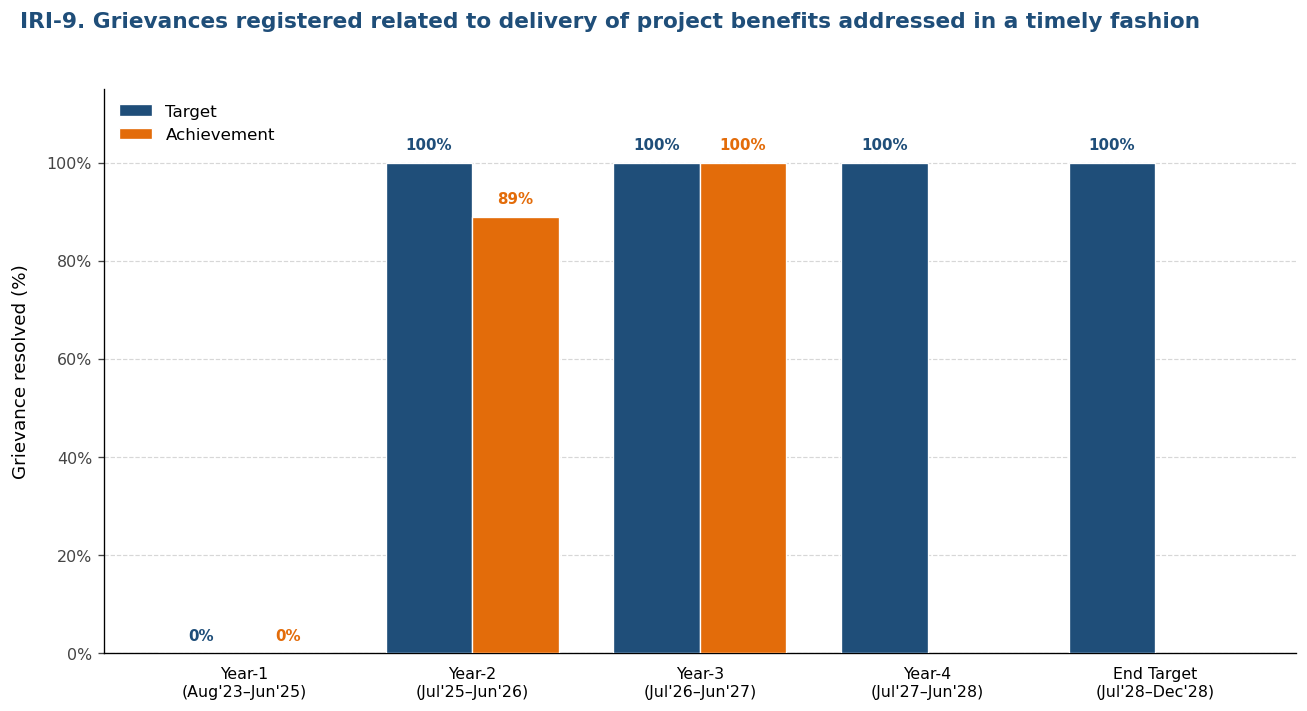

In [88]:
# IRI 9

years = [
    "Year-1\n(Aug'23–Jun'25)",
    "Year-2\n(Jul'25–Jun'26)",
    "Year-3\n(Jul'26–Jun'27)",
    "Year-4\n(Jul'27–Jun'28)",
    "End Target\n(Jul'28–Dec'28)",
]

target      = [0, 100, 100, 100, 100]
achievement = [0, 89, 100, np.nan, np.nan]

# ------------------------------------------------------------------
# 2. Figure & style
# ------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
fig.patch.set_facecolor("white")

# ------------------------------------------------------------------
# 3. Grouped bars
# ------------------------------------------------------------------
x = np.arange(len(years))
bar_width = 0.38

target_plot = np.array([v if not np.isnan(v) else 0 for v in target], dtype=float)
ach_plot    = np.array([v if not np.isnan(v) else 0 for v in achievement], dtype=float)
ach_mask    = ~np.isnan(np.array(achievement, dtype=float))

bars_target = ax.bar(x - bar_width/2, target_plot, width=bar_width,
                     color="#1f4e79", edgecolor="white", linewidth=0.8,
                     label="Target", zorder=3)

bars_ach = ax.bar(x + bar_width/2, ach_plot, width=bar_width,
                  color="#E36C0A", edgecolor="white", linewidth=0.8,
                  label="Achievement", zorder=3)

# Hide ONLY the achievement bars with no data (Years 4 & End Target)
for i, bar in enumerate(bars_ach):
    if not ach_mask[i]:
        bar.set_visible(False)

# ------------------------------------------------------------------
# 4. Data labels — one per visible bar, no skipping, no shared label
# ------------------------------------------------------------------
def bar_labels(bars, values, color, formatter, visible_mask=None):
    for i, (bar, v) in enumerate(zip(bars, values)):
        if visible_mask is not None and not visible_mask[i]:
            continue
        h = bar.get_height()
        ax.annotate(formatter(v),
                    xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 6),
                    textcoords="offset points",
                    ha="center", va="bottom",
                    fontsize=9, fontweight="bold", color=color)

# Target labels — every bar gets its own label (including Year-1 = 0%)
bar_labels(bars_target, target, "#1f4e79",
           formatter=lambda v: f"{int(v)}%")

# Achievement labels — only visible bars (years with real data)
bar_labels(bars_ach, achievement, "#E36C0A",
           formatter=lambda v: f"{int(v)}%",
           visible_mask=ach_mask)

# ------------------------------------------------------------------
# 5. Axes & formatting
# ------------------------------------------------------------------
ax.set_ylim(0, 115)   # room above the 100% bars for their labels
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{int(v)}%"))
ax.set_ylabel("Grievance resolved (%)", fontsize=11, labelpad=10)

ax.set_xticks(x)
ax.set_xticklabels(years, fontsize=9.5)
ax.tick_params(axis="x", length=0, pad=8)
ax.tick_params(axis="y", labelsize=9.5, colors="#444444")

ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)
ax.set_axisbelow(True)

# ------------------------------------------------------------------
# 6. Title
# ------------------------------------------------------------------
fig.suptitle(
    "IRI-9. Grievances registered related to delivery of project benefits addressed in a timely fashion",
    fontsize=13, fontweight="bold", color="#1f4e79",
    x=0.02, ha="left", y=0.98
)

# ------------------------------------------------------------------
# 7. Legend
# ------------------------------------------------------------------
ax.legend(loc="upper left", frameon=False, fontsize=10)

# ------------------------------------------------------------------
# 8. Layout & save
# ------------------------------------------------------------------
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("11a. IRI-9 Grievance.jpg",
            dpi=200, bbox_inches="tight",
            facecolor="white", edgecolor="none",
            pil_kwargs={"quality": 95})
plt.show()